# easyspec tutorial 2: photometry of a globular cluster (aperture, PSF and surface)

A globular cluster is the hardest case for photometry: hundreds of thousands of stars crowded in a few arcminutes, on top of the diffuse
light of the stars that are too faint to be seen individually. We use the globular cluster `SYN-GLOBULAR-1` of
`easyspec_photometry_synthetic_data/`, in B and V, and the standard-star field for the calibration.


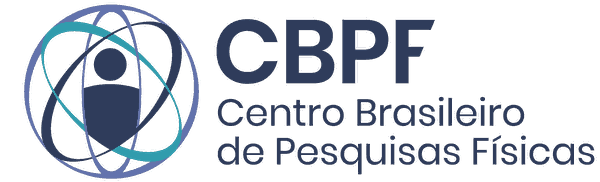

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from easyspec.cleaning import cleaning
from easyspec.photometry import photometry

data = Path("eso_NGC_1904_photometry")
out = Path("photometry_output_globular")
out.mkdir(exist_ok=True)

## 1. Reduction with `cleaning`

As in tutorial 1, one `cleaning` session per filter, and the frames of each object aligned and combined into one image. Three things are
specific to EFOSC, and all come from the header:

- **Trim**: the images (2x2 binning) have 1030 x 1030 pixels; the last 8 columns are overscan, and the top rows and the first columns
  are not fully illuminated. We keep x = 5-1018 and y = 0-1012.
- **Gain**: `ESO DET OUT1 CONAD` = 1.1 electrons per ADU (careful: `ESO DET OUT1 GAIN` is the inverse, in ADU per electron).
- **Read noise**: `ESO DET OUT1 RON` = 7.8 electrons.

In [2]:
# Header keywords of EFOSC
gain_keyword = "ESO DET OUT1 CONAD"          # electrons per ADU
read_noise_keyword = "ESO DET OUT1 RON"      # electrons
airmass_keyword = "ESO TEL AIRM START"

def reduce_filter(band, plot=False):
    c = cleaning()

    # Folders of this filter: the cluster and the three standard fields (TPhe, SA101-341 and PG0918+029), one folder per field
    bias_folder = data/"bias"
    flat_folder = data/f"flats_{band}"
    cluster_folder = data/f"NGC_1904_{band}"
    standard_folders = [data/f"standard_{band}", data/f"standard2_{band}", data/f"standard3_{band}"]

    # Read the raw frames. The standard fields are given as "targets": master() then combines the frames of each folder separately
    # (Type="standard_star" would combine all the standard frames together, mixing the three fields)
    raw = c.data_paths(bias=str(bias_folder), flats=str(flat_folder),
                       targets=[str(cluster_folder)] + [str(folder) for folder in standard_folders])

    # Remove the overscan and the edges that are not fully illuminated
    trimmed = c.trim(raw, x1=5, x2=1018, y1=0, y2=1012)

    # Bias
    master_bias = c.master("bias", trimmed, plot=False)
    debiased = c.debias(trimmed, master_bias)

    # Flat field
    master_flat = c.master("flat", debiased, plot=False)
    norm_flat = c.norm_master_flat(master_flat, method="imaging", plots=False)
    flattened = c.flatten(debiased, norm_flat)

    # ADU -> electrons, cosmic rays, and the variance of every pixel (gain and read noise read from the header of each frame)
    electrons = c.gain_correct(flattened, gain_header_entry=gain_keyword, verbose=False)
    cleaned = c.remove_cosmic_rays(electrons, readnoise_header_entry=read_noise_keyword, verbose=False)
    variance, mask = c.compute_variance(cleaned, readnoise_header_entry=read_noise_keyword, verbose=False)

    # Align the frames of each folder onto its first frame (the variance and the mask follow the images). crop=False keeps the full
    # field: where a shifted frame has no data, its pixels are NaN (ignored by the photometry)
    aligned, aligned_variance, aligned_mask = c.align(cleaned, Type="target", crop=False, fill_value=np.nan,
                                                      variance=variance, mask=mask)

    # Combine the frames of each folder into one image (mean: keeps the flux of the stars; exposure time and airmass = means)
    c.master("target", aligned, method="mean", exposure_header_entry="EXPTIME", airmass_header_entry=airmass_keyword,
             variance=aligned_variance, mask=aligned_mask, plot=plot)

    # master() writes one file per folder in the working directory (master_target_<folder>.fits): move them to the output folders
    (out/f"NGC1904_{band}").mkdir(exist_ok=True)
    (out/f"standards_{band}").mkdir(exist_ok=True)
    Path(f"master_target_{cluster_folder.name}.fits").replace(out/f"NGC1904_{band}"/f"master_target_{cluster_folder.name}.fits")
    for folder in standard_folders:
        Path(f"master_target_{folder.name}.fits").replace(out/f"standards_{band}"/f"{folder.name}.fits")

Normalized master flat: 1012/1012 illuminated rows; median = 0.9800; robust scatter = 0.0216; 555 pixels set to 1 (low signal).
24 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.29%, from 0.28% to 0.32% depending on the column.
Group 'NGC_1904_B' - reference image: EFOSC.2009-12-01T06:13:35.599.fits
  EFOSC.2009-12-01T06:14:11.453.fits: method = stars, rotation = -0.007 deg, center shift (dx, dy) = (+20.52, +20.57) px, matched stars = 57, rms = 0.293 px
  EFOSC.2009-12-01T06:14:47.497.fits: method = stars, rotation = -0.009 deg, center shift (dx, dy) = (+41.06, +41.28) px, matched stars = 56, rms = 0.311 px
  EFOSC.2009-12-01T06:20:09.653.fits: method = stars, rotation = -0.003 deg, center shift (dx, dy) = (-0.36, -2.67) px, matched stars = 56, rms = 0.258 px
  EFOSC.2009-12-01T06:20:45.387.fits: method = stars, rotation = -0.005 deg, center shift (dx, dy) = (+20.14, +18.62) px, matched stars = 57, rms = 0.

/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:535: RuntimeWarning: invalid value encountered in subtract
  independent = sum(np.clip(np.asarray(variance[frame], dtype=float) - c, 0, None)
/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:332: UserWarning: The frames combined into the master target have different exposure times (1.0005 to 1.0006). Consider normalizing them by their exposure times before combining.
  warnings.warn(f"The frames combined into the master {Type} have different exposure times "


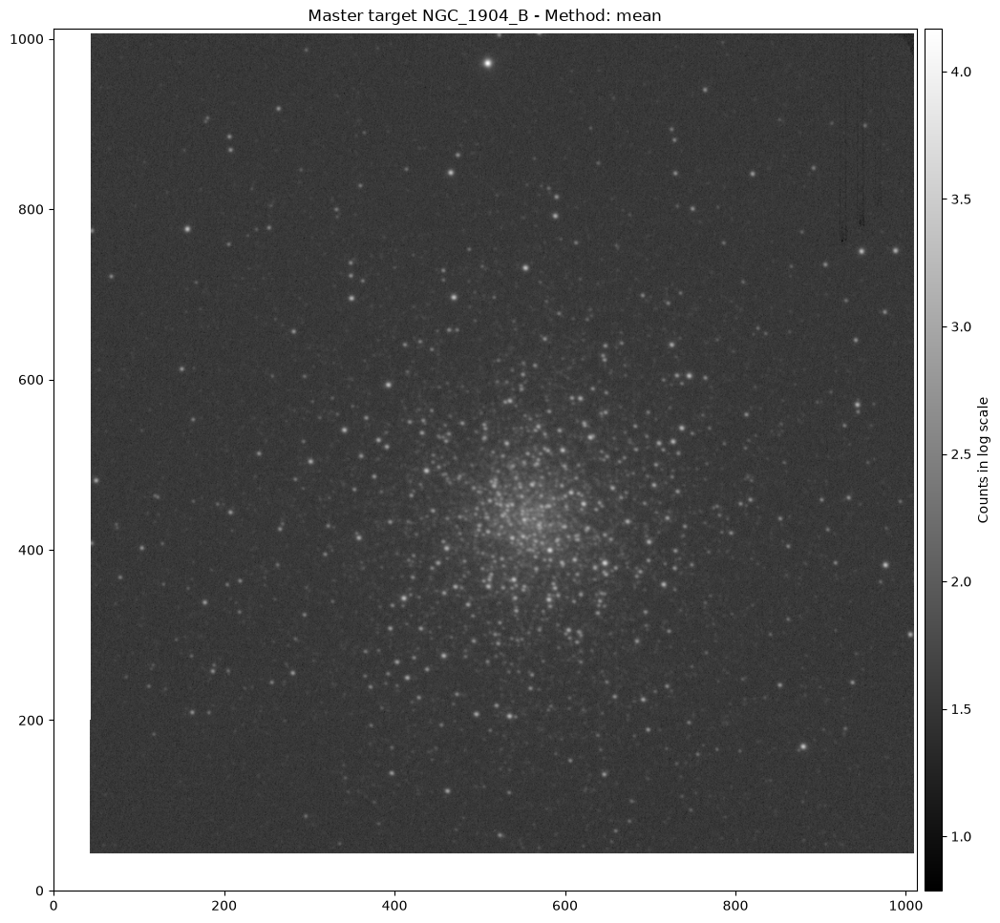

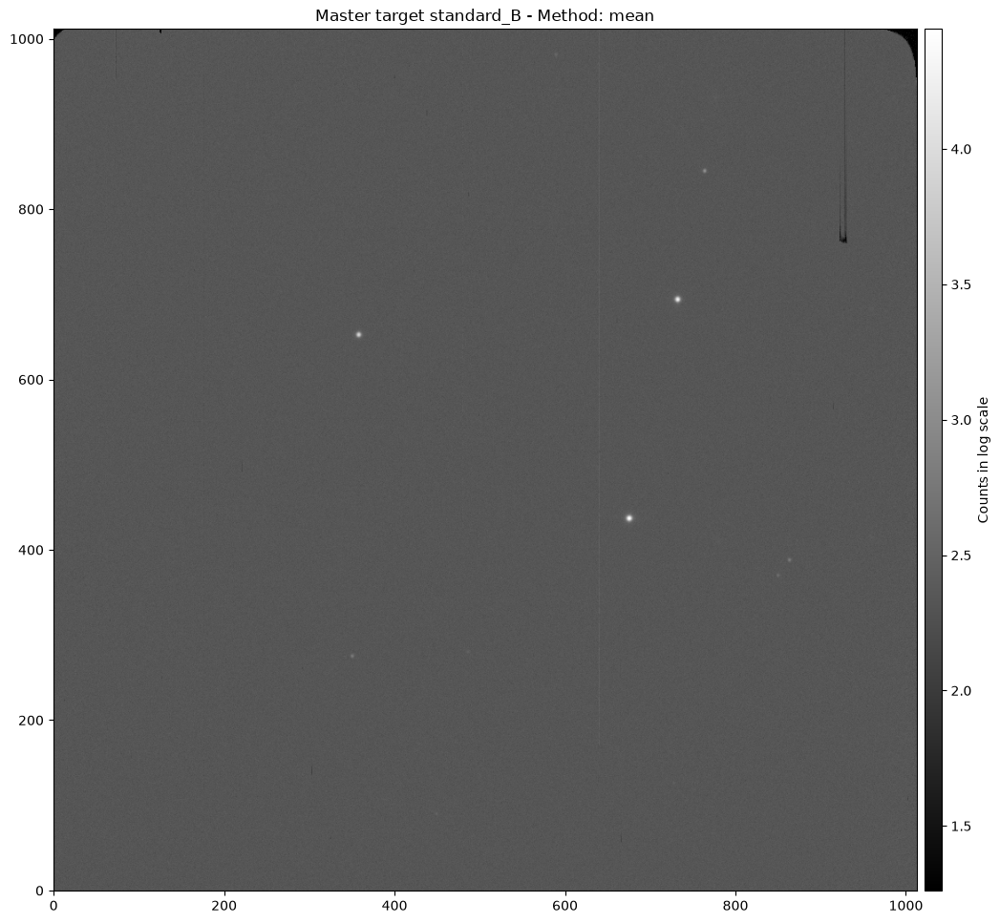

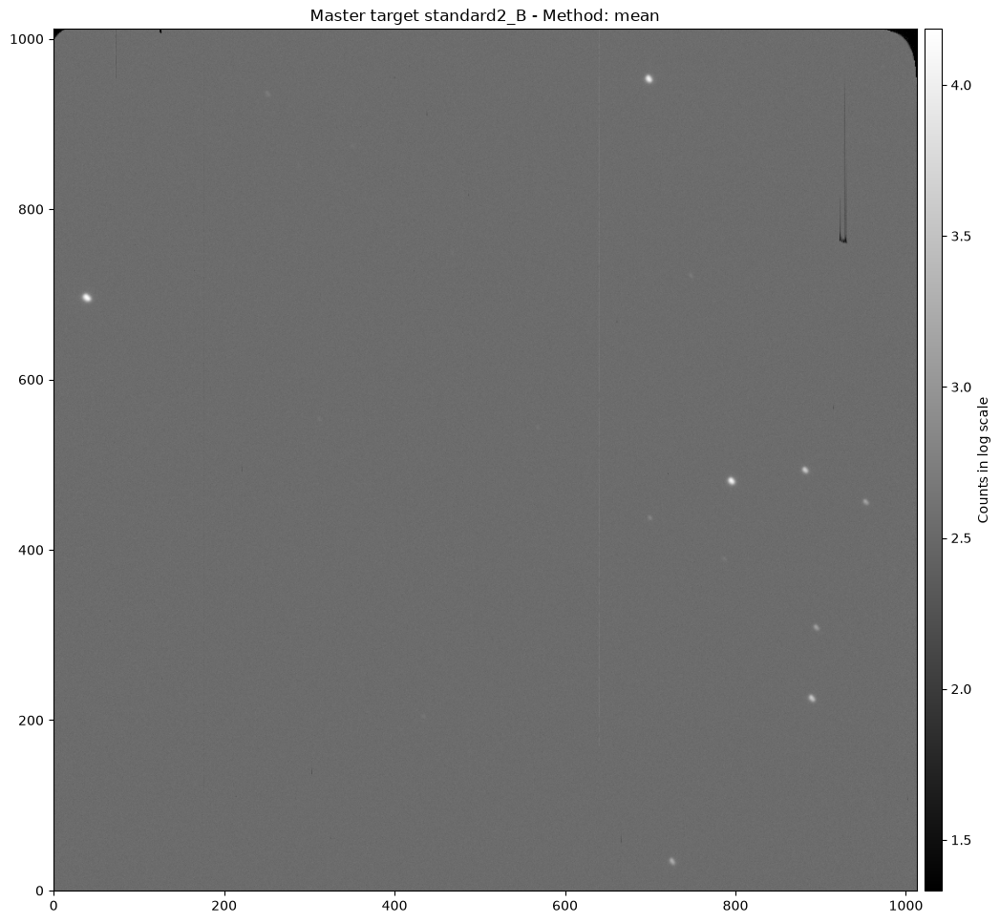

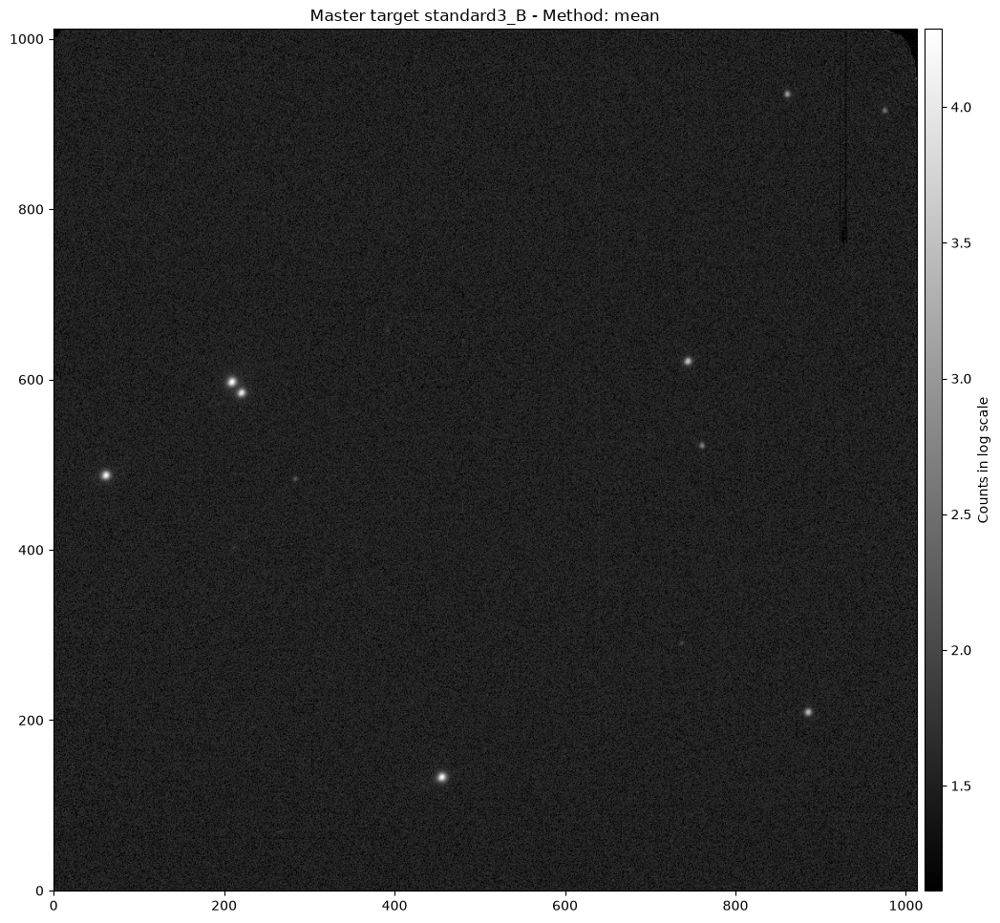

Normalized master flat: 1012/1012 illuminated rows; median = 0.9914; robust scatter = 0.0091; 388 pixels set to 1 (low signal).
28 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.28%, from 0.24% to 0.38% depending on the column.
Group 'NGC_1904_V' - reference image: EFOSC.2009-12-01T06:15:38.347.fits
  EFOSC.2009-12-01T06:16:14.141.fits: method = stars, rotation = -0.000 deg, center shift (dx, dy) = (+20.96, +20.67) px, matched stars = 59, rms = 0.167 px
  EFOSC.2009-12-01T06:16:49.935.fits: method = stars, rotation = -0.003 deg, center shift (dx, dy) = (+41.05, +40.87) px, matched stars = 58, rms = 0.183 px
  EFOSC.2009-12-01T06:22:11.831.fits: method = stars, rotation = +0.003 deg, center shift (dx, dy) = (-0.34, -2.11) px, matched stars = 60, rms = 0.168 px
  EFOSC.2009-12-01T06:22:47.545.fits: method = stars, rotation = +0.002 deg, center shift (dx, dy) = (+20.13, +18.07) px, matched stars = 59, rms = 0.

/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:535: RuntimeWarning: invalid value encountered in subtract
  independent = sum(np.clip(np.asarray(variance[frame], dtype=float) - c, 0, None)
/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:332: UserWarning: The frames combined into the master target have different exposure times (1.0005 to 1.0006). Consider normalizing them by their exposure times before combining.
  warnings.warn(f"The frames combined into the master {Type} have different exposure times "
/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:535: RuntimeWarning: invalid value encountered in subtract
  independent = sum(np.clip(np.asarray(variance[frame], dtype=float) - c, 0, None)
/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:332: UserWarning: The frames combined into the maste

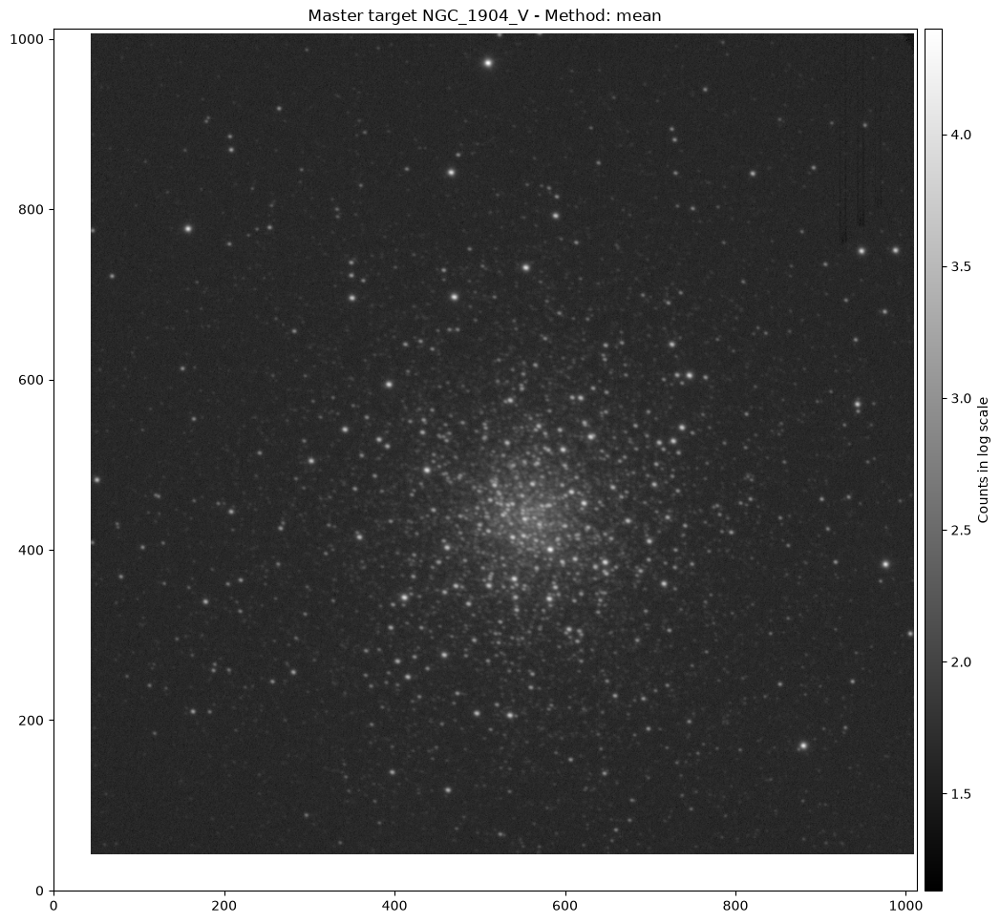

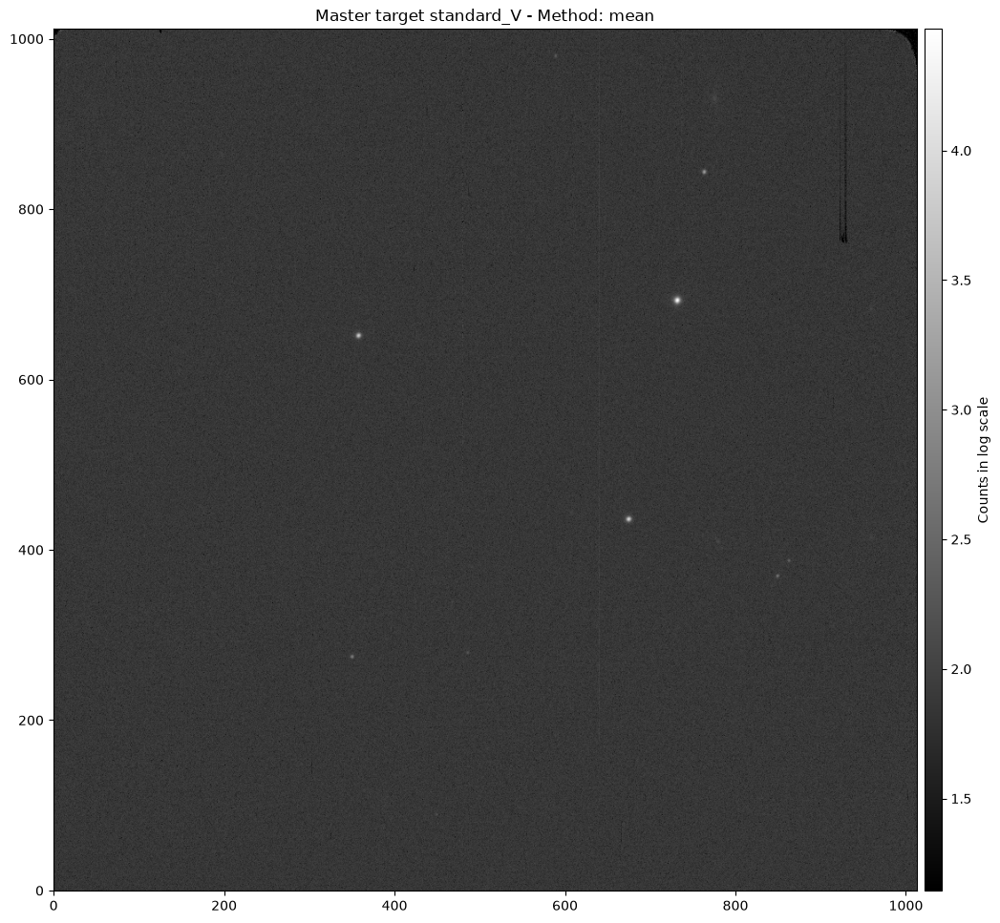

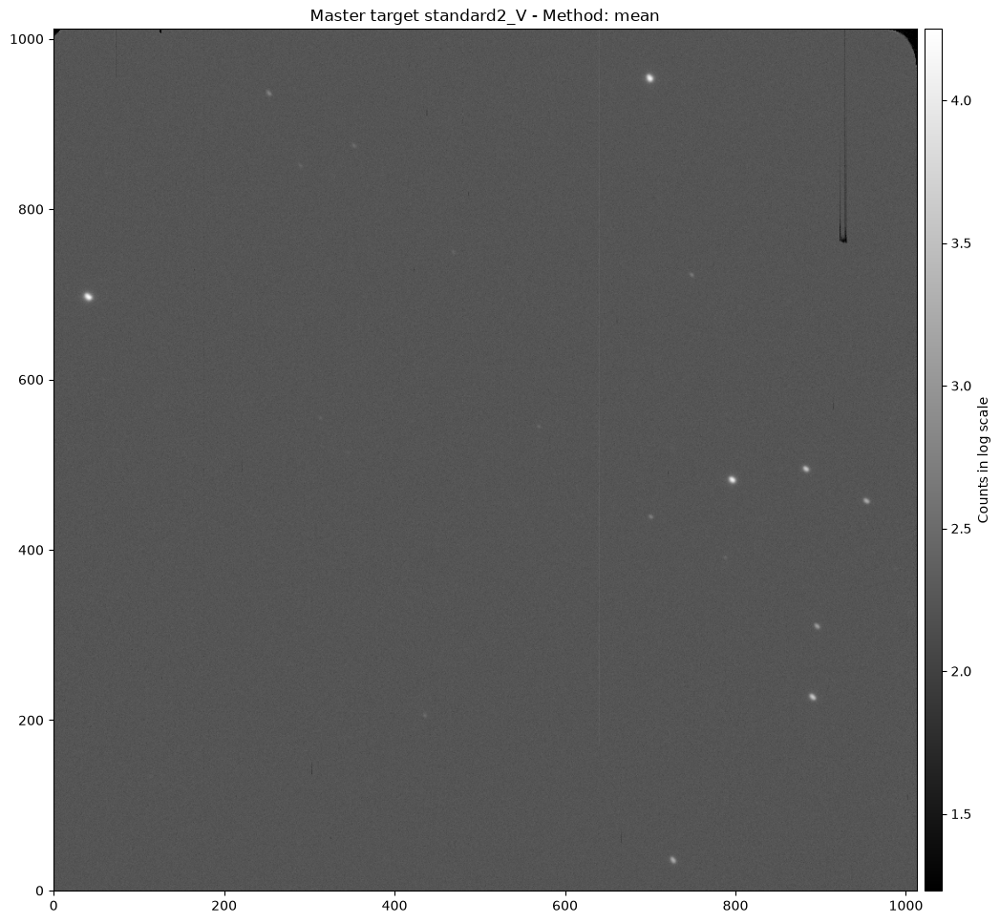

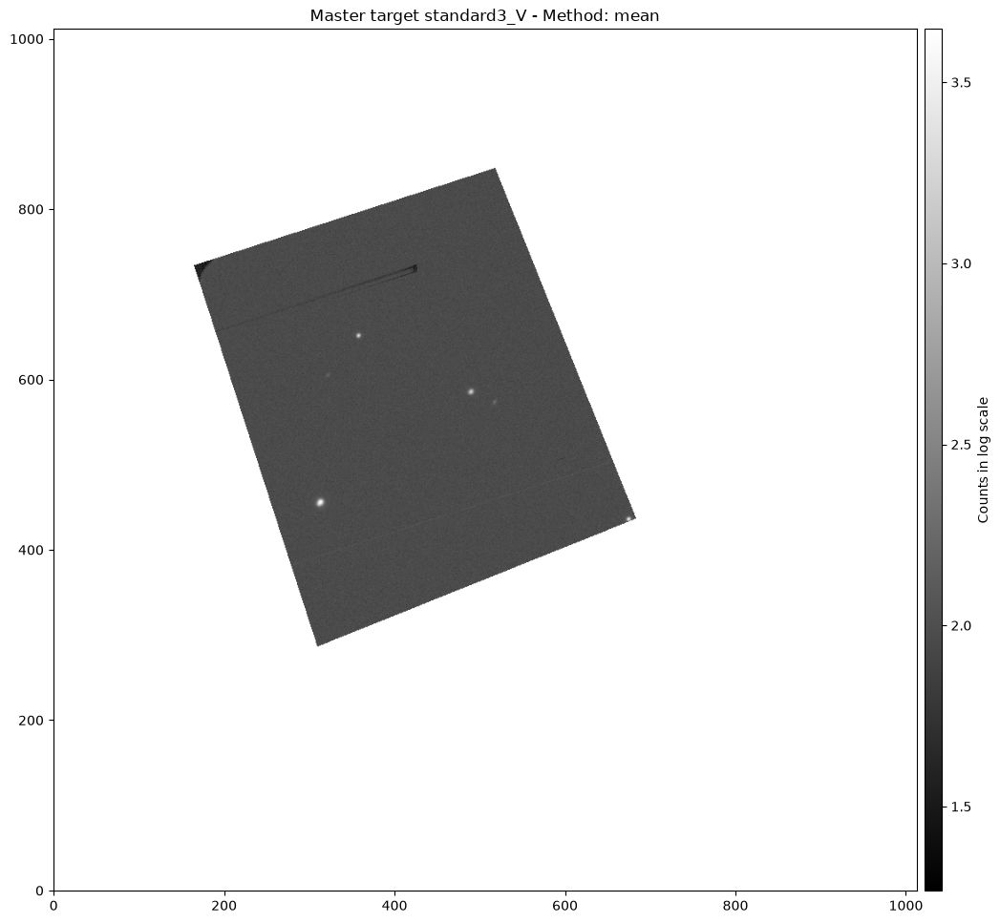

Normalized master flat: 1012/1012 illuminated rows; median = 0.9999; robust scatter = 0.0060; 202 pixels set to 1 (low signal).
26 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.24%, from 0.20% to 2.07% depending on the column.
Group 'NGC_1904_R' - reference image: EFOSC.2009-12-01T06:17:40.725.fits
  EFOSC.2009-12-01T06:18:16.579.fits: method = stars, rotation = -0.002 deg, center shift (dx, dy) = (+21.45, +20.69) px, matched stars = 58, rms = 0.161 px
  EFOSC.2009-12-01T06:18:52.053.fits: method = stars, rotation = -0.006 deg, center shift (dx, dy) = (+41.66, +40.99) px, matched stars = 57, rms = 0.169 px
  EFOSC.2009-12-01T06:24:14.809.fits: method = stars, rotation = +0.002 deg, center shift (dx, dy) = (+0.00, -1.86) px, matched stars = 59, rms = 0.145 px
  EFOSC.2009-12-01T06:24:50.743.fits: method = stars, rotation = -0.002 deg, center shift (dx, dy) = (+20.94, +19.38) px, matched stars = 59, rms = 0.

/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:535: RuntimeWarning: invalid value encountered in subtract
  independent = sum(np.clip(np.asarray(variance[frame], dtype=float) - c, 0, None)
/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/easyspec/cleaning/cleaning.py:332: UserWarning: The frames combined into the master target have different exposure times (1.0005 to 1.0006). Consider normalizing them by their exposure times before combining.
  warnings.warn(f"The frames combined into the master {Type} have different exposure times "


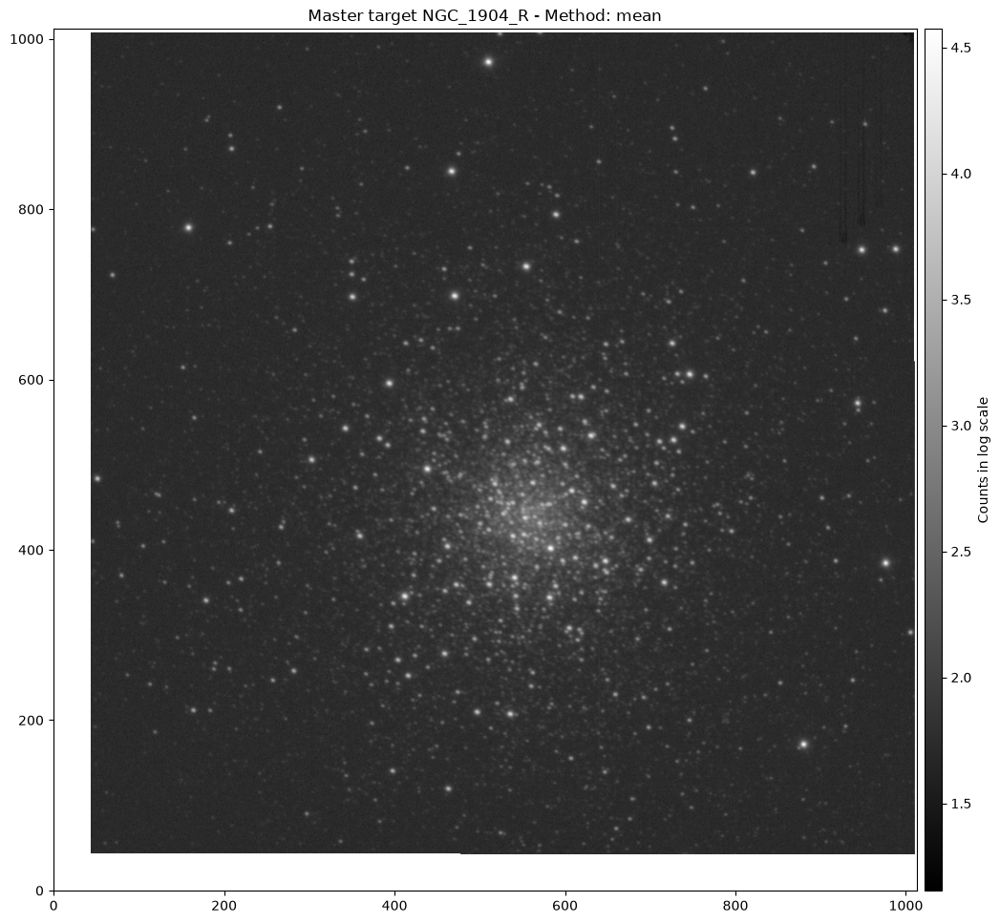

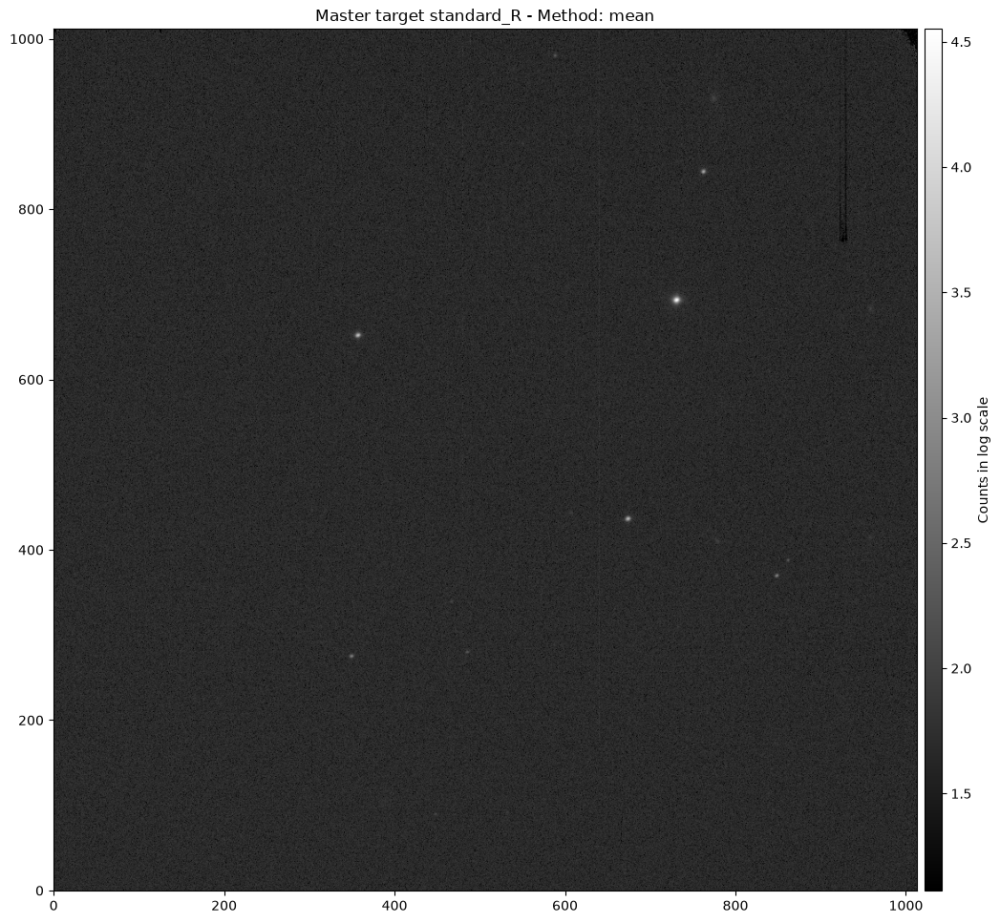

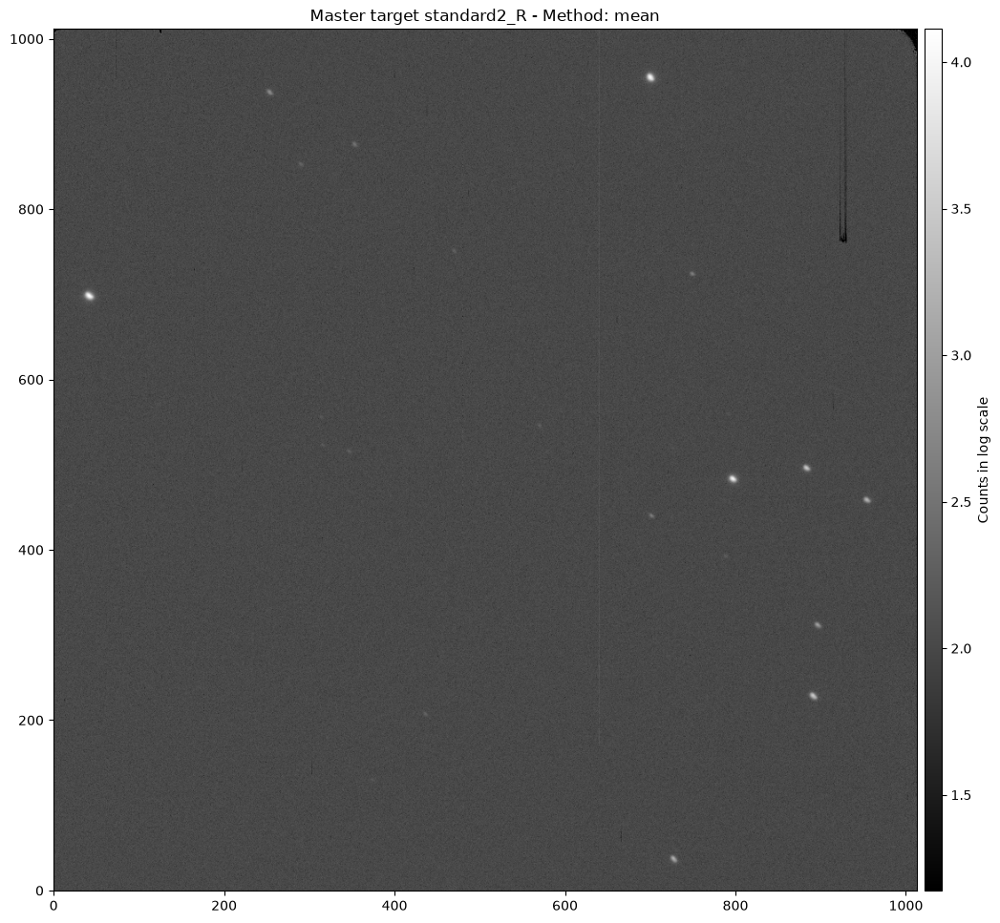

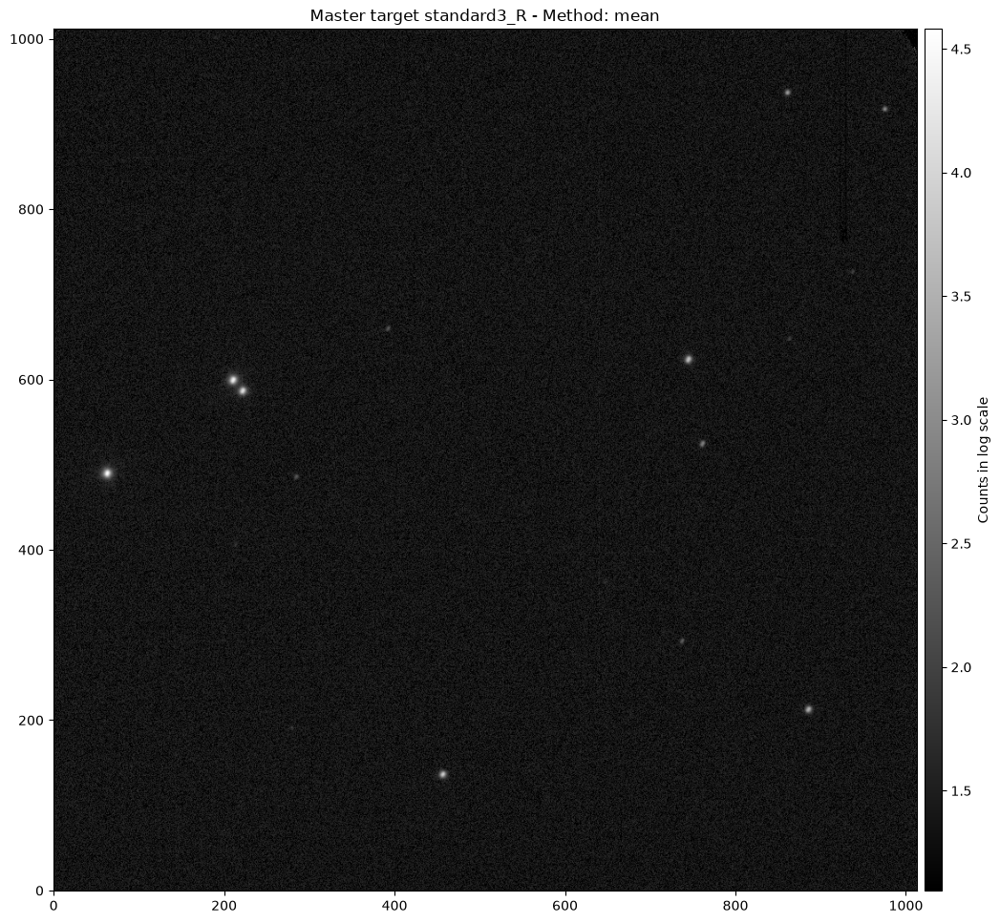

In [3]:
for band in ("B", "V", "R"):
    reduce_filter(band, plot=True)

Let's create a colored image:

Exposure times: NGC1904_B/master_target_NGC_1904_B.fits = 1.00056 s, NGC1904_V/master_target_NGC_1904_V.fits = 1.00052 s, NGC1904_R/master_target_NGC_1904_R.fits = 1.00054 s
Group 'colored image' - reference image: master_target_NGC_1904_B.fits
  master_target_NGC_1904_V.fits: method = stars, rotation = -0.011 deg, center shift (dx, dy) = (-0.43, -0.66) px, matched stars = 54, rms = 0.366 px
  master_target_NGC_1904_R.fits: method = stars, rotation = -0.004 deg, center shift (dx, dy) = (-0.76, -2.12) px, matched stars = 53, rms = 0.433 px
Region with data in all 3 bands: x = 0-1012, y = 0-1009 (1012 x 1009 pixels)


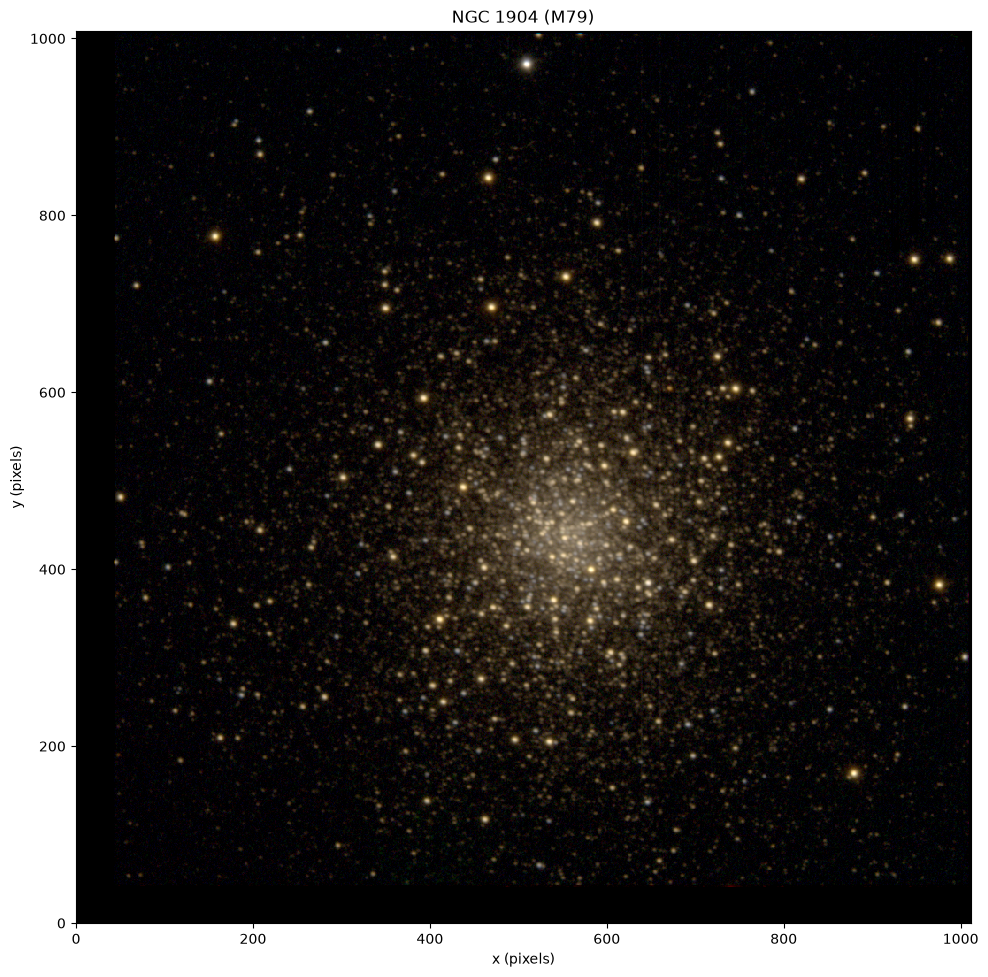

In [4]:
c = cleaning()

cluster_images = [out/"NGC1904_B"/"master_target_NGC_1904_B.fits",
                  out/"NGC1904_V"/"master_target_NGC_1904_V.fits",
                  out/"NGC1904_R"/"master_target_NGC_1904_R.fits"]
colors = ["blue", "green", "red"]                    # one color per image: names, hex ("#ff8800") or (r, g, b) tuples

colored = c.generate_colored_image(cluster_images, colors,
                                   remove_saturated_pixels=False,  # True removes the vertical bleeding trails of saturated stars
                                   remove_stars=False,             # True subtracts the stars (PSF), to show only the diffuse light
                                   band_scaling="exposure",        # common flux scale; "separate": each band on its own (more color)
                                   zero_points=None,               # e.g. the ZPs of the calibration: colors relative to Vega
                                   white_percentile=99.99,         # percentile that becomes white (lower = brighter image)
                                   black_level=0.0,                # black point in sky sigmas (> 0 hides the sky noise)
                                   band_weights=None,              # e.g. [1.1, 1.0, 0.9]: color balance
                                   smoothing_sigma=0.0,            # Gaussian smoothing in pixels, to reduce the noise
                                   stretch="log",                  # "log", "asinh" or "linear"
                                   stretch_strength=None,          # larger = fainter stars visible (default 1000 for "log")
                                   color_mode="channels",          # "channels" (as DS9) or "preserve" (colors kept up to the star cores)
                                   gamma=1.0, color_saturation=1.0, contrast=1.0, brightness=1.0,
                                   region=None,                    # (x1, x2, y1, y2): zoom on a part of the image
                                   plot_diagnostic=False,          # True: show the aligned images before the cut
                                   plot_result=True,
                                   title="NGC 1904 (M79)", show_axes=True,
                                   output_file=None)               # e.g. out/"NGC1904_color.png" (or .fits)

## 2. Photometric calibration

As in tutorial 1 (see the explanation there), with one difference: these images have a WCS (astrometric solution) in their headers,
which `cleaning` kept through the trim, the alignment and the combination. So we do not need to identify the standard stars by hand:
easyspec takes their coordinates and magnitudes from Landolt's catalogue (`catalogue="landolt"`) and finds them on the images by itself.
We make two solutions: B − V for the B and V magnitudes, and V − R for R.

In [5]:
phot = photometry()

# Header keywords of EFOSC
filter_keyword = "ESO INS FILT1 NAME"
airmass_keyword = "ESO TEL AIRM START"
gain_keyword = "ESO DET OUT1 CONAD"
band_names = {"B#639": "B", "V#641": "V", "R#642": "R"}     # EFOSC filter names -> short names used in the tables
saturation_level = 65535                                      # ADU: no saturation keyword in the header

# The three standard fields (TPhe, SA101-341 and PG0918+029): one image per field and per filter
standard_folders = [out/"standards_B", out/"standards_V", out/"standards_R"]
standards = phot.load_images(standard_folders, band_header_entry=filter_keyword, airmass_header_entry=airmass_keyword,
                             gain_header_entry=gain_keyword, band_names=band_names, saturation_level=saturation_level)
standard_photometry = phot.aperture_photometry(standards)       # one table per image: 3 fields x 3 filters

for image in standards:
    print(f"{image.extra['path']}: {image.object_name}, band {image.band}, {image.exposure_time:.1f} s, airmass {image.airmass:.3f}")

standard2_B.fits: band B, 15.0005 s, airmass 1.413, 1013x1012 px, WCS: yes
standard3_B.fits: band B, 3.0006 s, airmass 1.219, 1013x1012 px, WCS: yes
standard_B.fits: band B, 8.0006 s, airmass 1.094, 1013x1012 px, WCS: yes
standard2_V.fits: band V, 6.0005 s, airmass 1.409, 1013x1012 px, WCS: yes
standard3_V.fits: band V, 3.3339 s, airmass 1.2403333333333333, 1013x1012 px, WCS: yes
standard_V.fits: band V, 2.0006 s, airmass 1.095, 1013x1012 px, WCS: yes
standard2_R.fits: band R, 3.0005 s, airmass 1.405, 1013x1012 px, WCS: yes
standard3_R.fits: band R, 1.0006 s, airmass 1.216, 1013x1012 px, WCS: yes
standard_R.fits: band R, 1.0006 s, airmass 1.096, 1013x1012 px, WCS: yes
standard2_B.fits: FWHM = 4.51 px (1.09 arcsec), scatter 0.24 px from 9 stars; sky = 351.0 e-, RMS = 21.18 e-; 23 sources above 5.0 sigma
standard2_B.fits: 23 stars (12 unflagged); aperture 5.4 px, annulus 20.3-29.3 px; aperture correction -0.082 mag from 3 stars (scatter 0.9%); background noise factor 1.00
standard3_B.fit

standards observed at airmass 1.09-1.41: extinction fitted


standard2_B.fits: 9 of the 27 catalogue stars on the image matched (WCS offset dx = -45.3, dy = -34.9 px)
standard3_B.fits: 6 of the 17 catalogue stars on the image matched (WCS offset dx = -26.6, dy = -58.5 px)
standard_B.fits: 4 of the 12 catalogue stars on the image matched (WCS offset dx = +44.0, dy = +38.7 px)
standard2_V.fits: 8 of the 28 catalogue stars on the image matched (WCS offset dx = -44.3, dy = -34.4 px)
standard3_V.fits: 2 of the 6 catalogue stars on the image matched (WCS offset dx = +44.3, dy = +35.8 px)
standard_V.fits: 4 of the 12 catalogue stars on the image matched (WCS offset dx = +44.3, dy = +37.6 px)
Band B: ZP = 25.8805 +/- 0.0576, k = 0.2426 +/- 0.0469, c = -0.0498 +/- 0.0083 [color B-V]; rms = 0.0573 mag, reduced chi2 = 7.53, 19/19 measurements used
Band V: ZP = 25.8792 +/- 0.0409, k = 0.1025 +/- 0.0340, c = -0.0302 +/- 0.0062 [color B-V]; rms = 0.0603 mag, reduced chi2 = 2.86, 12/14 measurements used


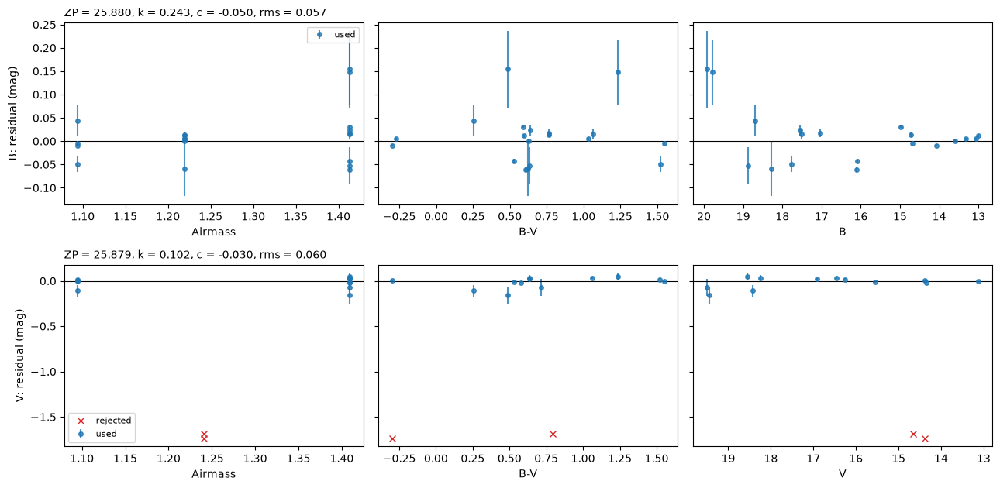

standard2_V.fits: 8 of the 28 catalogue stars on the image matched (WCS offset dx = -44.3, dy = -34.4 px)
standard3_V.fits: 2 of the 6 catalogue stars on the image matched (WCS offset dx = +44.3, dy = +35.8 px)
standard_V.fits: 4 of the 12 catalogue stars on the image matched (WCS offset dx = +44.3, dy = +37.6 px)
standard2_R.fits: 10 of the 25 catalogue stars on the image matched (WCS offset dx = -43.4, dy = -33.0 px)
standard3_R.fits: 3 of the 17 catalogue stars on the image matched (WCS offset dx = -25.2, dy = -57.8 px)
standard_R.fits: 3 of the 12 catalogue stars on the image matched (WCS offset dx = +43.8, dy = +37.4 px)
Band V: ZP = 25.8801 +/- 0.0386, k = 0.1045 +/- 0.0322, c = -0.0550 +/- 0.0104 [color V-R]; rms = 0.0595 mag, reduced chi2 = 2.56, 12/14 measurements used
Band R: ZP = 26.0574 +/- 0.0370, k = 0.1550 +/- 0.0287, c = -0.0630 +/- 0.0135 [color V-R]; rms = 0.0327 mag, reduced chi2 = 0.86, 16/16 measurements used


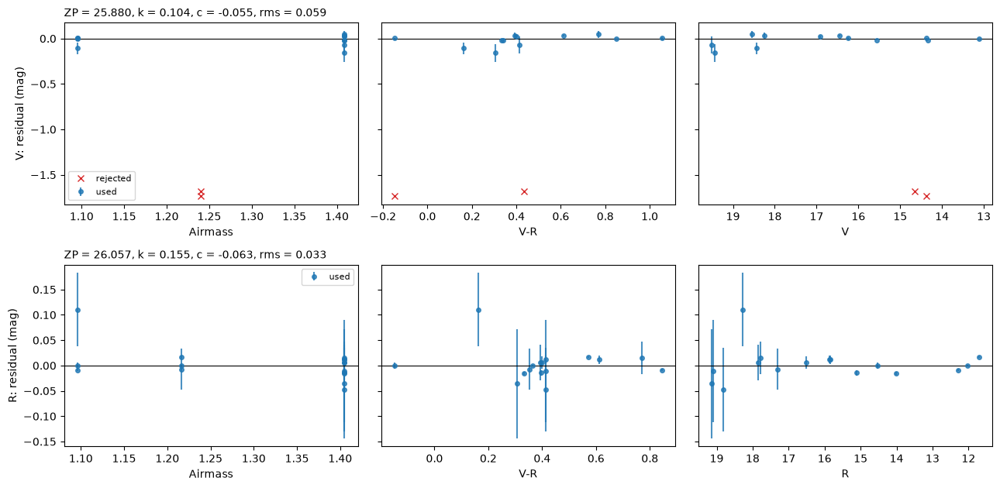

In [6]:
from astropy.table import vstack

# All the standards of easyspec: the bright ones of Landolt and the faint ones of Clem & Landolt (a star in both catalogues is used once)
all_standards = vstack([phot.standard_star_catalogue("landolt"), phot.standard_star_catalogue("clem_landolt")])

# Extinction: fitted if the standard fields were observed over a range of airmasses, otherwise fixed to the values measured by ESO
efosc_extinction = {"B": 0.251, "V": 0.132, "R": 0.096}     # mag per airmass
airmasses = [image.airmass for image in standards]
fit_extinction = max(airmasses) - min(airmasses) > 0.3
print(f"standards observed at airmass {min(airmasses):.2f}-{max(airmasses):.2f}: extinction "
      f"{'fitted' if fit_extinction else 'fixed to the values of ESO'}")

# search_radius=60: the WCS of EFOSC comes from the pointing of the telescope and is off by ~13" (~55 pixels)
solution_BV = phot.fit_standard_star_solution(standard_photometry, catalogue=all_standards, bands=("B", "V"), color_index=("B", "V"),
                                              fit_extinction=fit_extinction, fixed_extinction=efosc_extinction, search_radius=60)
solution_VR = phot.fit_standard_star_solution(standard_photometry, catalogue=all_standards, bands=("V", "R"), color_index=("V", "R"),
                                              fit_extinction=fit_extinction, fixed_extinction=efosc_extinction, search_radius=60)

## 3. Aperture photometry (for comparison)

Aperture photometry is explained in tutorial 1. In a crowded field it suffers: the apertures and sky annuli contain light of the
neighbours, many stars are flagged as "crowded", and the faint stars of the core are not even detected.

In [7]:
# The cluster (one combined image per filter)
cluster_folders = [out/"NGC1904_B", out/"NGC1904_V", out/"NGC1904_R"]
cluster = phot.load_images(cluster_folders, band_header_entry=filter_keyword, airmass_header_entry=airmass_keyword,
                           gain_header_entry=gain_keyword, band_names=band_names, saturation_level=saturation_level)

B_aperture, V_aperture, R_aperture = phot.aperture_photometry(cluster)
aperture_BV = phot.calibrate_magnitudes([B_aperture, V_aperture], solution_BV)
aperture_VR = phot.calibrate_magnitudes([V_aperture, R_aperture], solution_VR)

master_target_NGC_1904_B.fits: band B, 1.00056 s, airmass 1.0226, 1013x1012 px, WCS: yes
master_target_NGC_1904_V.fits: band V, 1.00052 s, airmass 1.0244, 1013x1012 px, WCS: yes
master_target_NGC_1904_R.fits: band R, 1.00054 s, airmass 1.026, 1013x1012 px, WCS: yes
master_target_NGC_1904_B.fits: FWHM = 3.10 px (0.75 arcsec), scatter 0.08 px from 37 stars; sky = 34.7 e-, RMS = 5.12 e-; 735 sources above 5.0 sigma
master_target_NGC_1904_B.fits: 735 stars (666 unflagged); aperture 3.7 px, annulus 14.0-20.2 px; aperture correction -0.142 mag from 7 stars (scatter 0.0%); background noise factor 1.03
master_target_NGC_1904_V.fits: FWHM = 2.93 px (0.71 arcsec), scatter 0.18 px from 38 stars; sky = 45.4 e-, RMS = 5.78 e-; 1222 sources above 5.0 sigma
master_target_NGC_1904_V.fits: 1222 stars (1114 unflagged); aperture 3.5 px, annulus 13.2-19.1 px; aperture correction -0.140 mag from 16 stars (scatter 0.8%); background noise factor 1.04
master_target_NGC_1904_R.fits: FWHM = 2.80 px (0.67 arcsec

## 4. PSF photometry

Instead of adding up the light in a circle, PSF ("profile") photometry fits a model of the star image — the point spread function, PSF —
to each star. Where two stars overlap, both are fitted at the same time, so each one gets its own light. `psf_photometry()` does:

1. **Empirical PSF**: the shape of the stars is not a simple function (seeing, optics, the averaging of frames with different seeing), so
   it is built from the images of bright, isolated, unsaturated stars, aligned with sub-pixel precision and averaged (photutils
   EPSFBuilder, Anderson & King 2000).
2. **Simultaneous fits**: stars closer than ~2 FWHM form a group and are fitted together (position and flux of each one). Saturated pixels
   are left out of the fit, so saturated stars are measured with their wings.
3. **Iterations**: all fitted stars are subtracted from the image, and the residual image is searched for stars that were hidden (close
   companions, faint stars next to bright ones). The PSF is rebuilt with the neighbours of its stars subtracted (in a crowded field they
   contaminate its wings), and everything is fitted again. Three iterations by default.
4. **PSF-to-total correction**: the fluxes are brought to the scale of the total fluxes (the one of the standard-star calibration), like
   the aperture correction.

The uncertainties include an error floor for the imperfections of the PSF model (measured from the star-to-star scatter of step 4).
This step takes ~5 minutes per image.

master_target_NGC_1904_B.fits: FWHM = 3.10 px (0.75 arcsec), scatter 0.08 px from 37 stars; sky = 34.7 e-, RMS = 5.13 e-; 735 sources above 5.0 sigma
master_target_NGC_1904_B.fits: empirical PSF from 30 stars (stamp 23 px, oversampling 2)
   iteration 1: 735 stars fitted (grouping distance 2.00 FWHM), 216 new stars found in the residual image
   iteration 2: 951 stars fitted (grouping distance 2.00 FWHM), 32 new stars found in the residual image
master_target_NGC_1904_B.fits: 978 stars (542 unflagged); PSF-to-total correction +0.023 mag from 20 stars; background noise factor 1.00


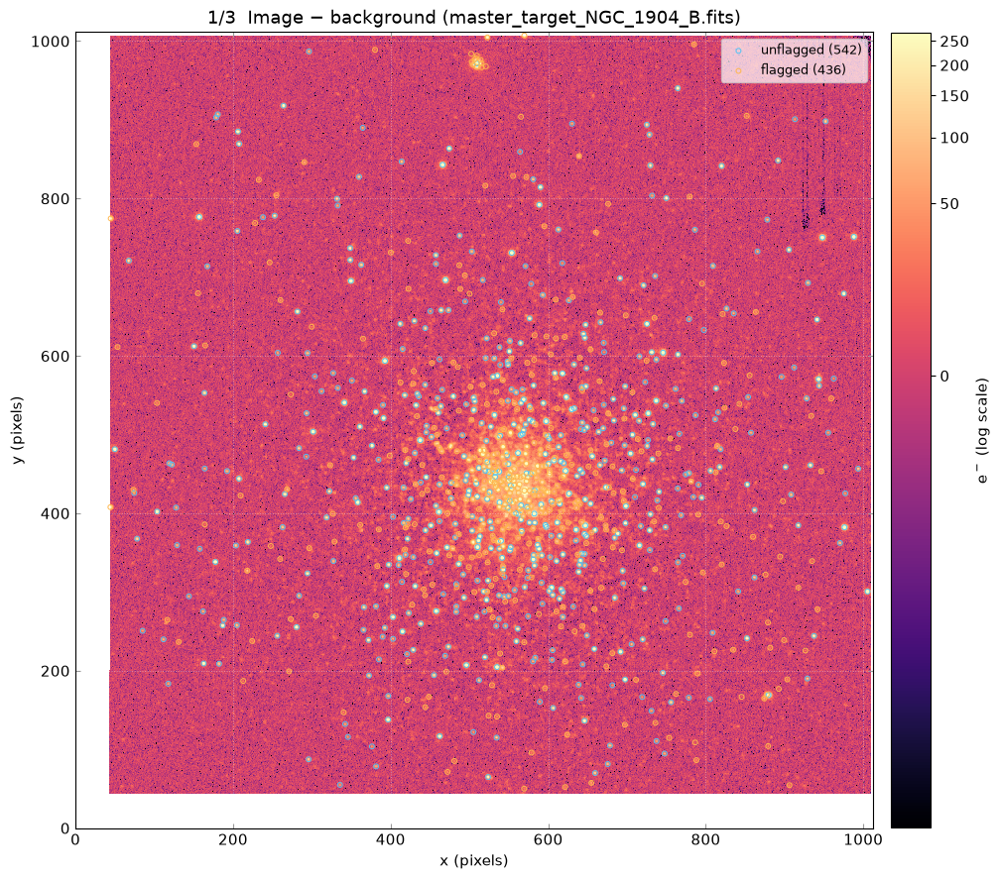

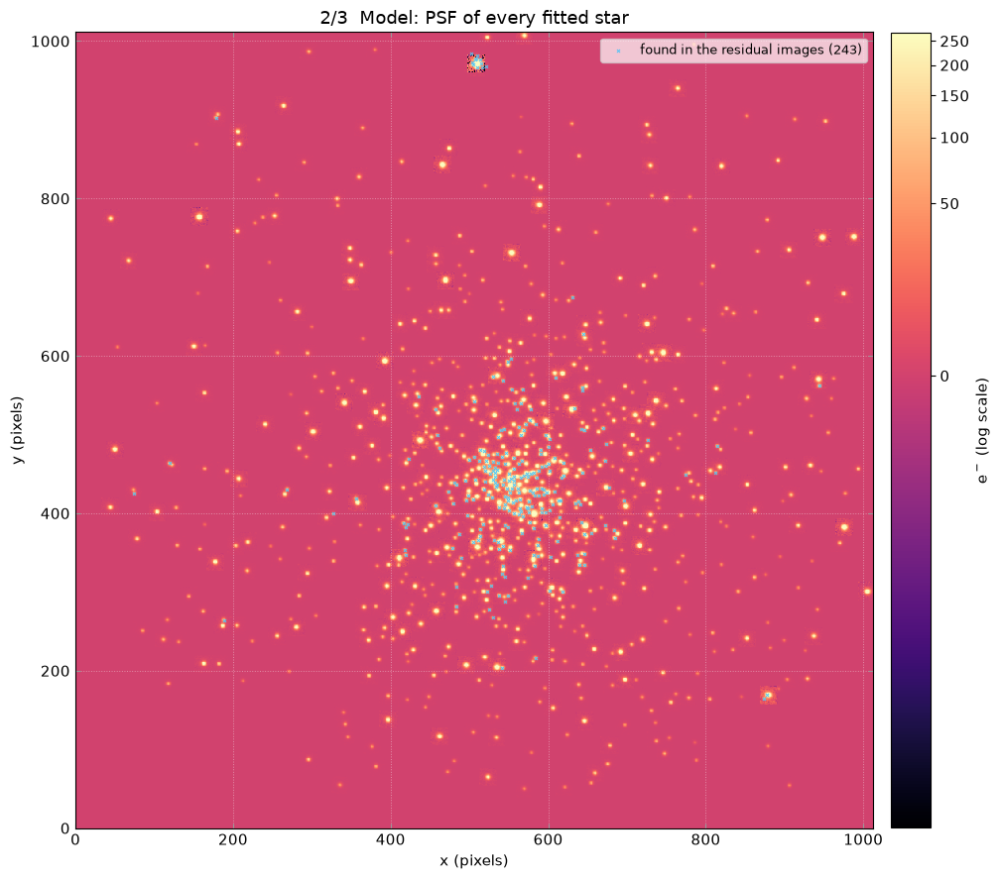

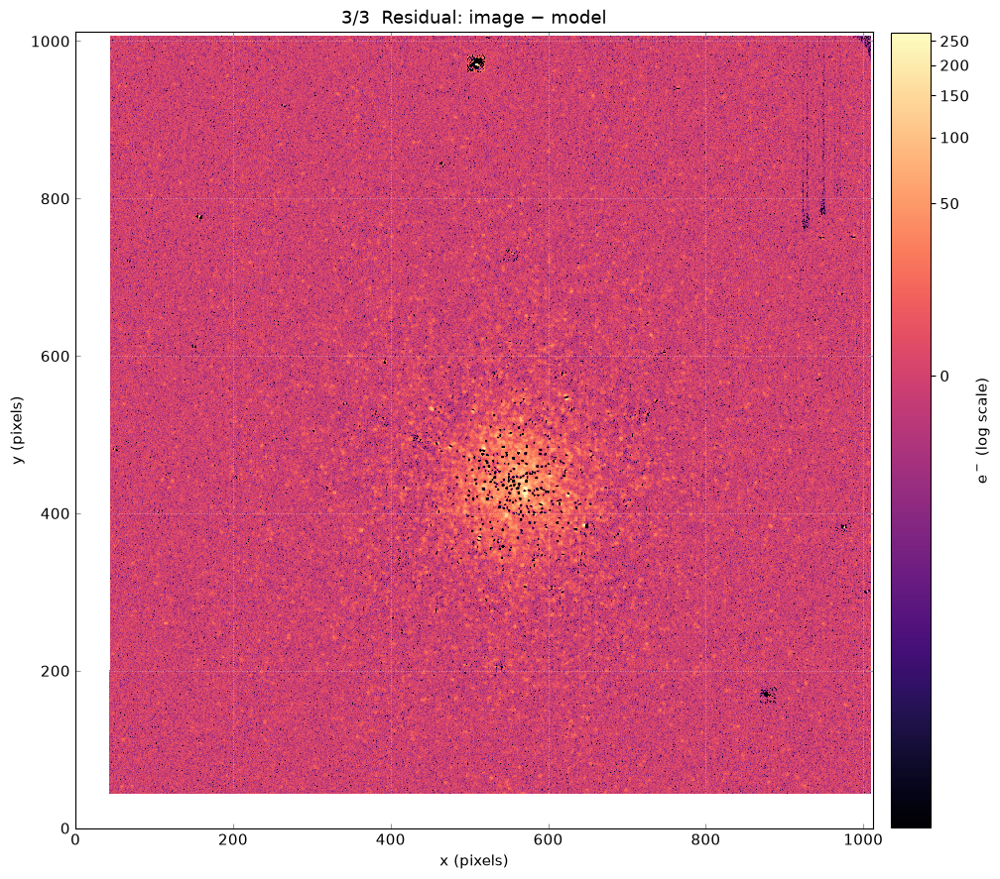

master_target_NGC_1904_V.fits: FWHM = 2.91 px (0.70 arcsec), scatter 0.16 px from 38 stars; sky = 45.3 e-, RMS = 5.74 e-; 1234 sources above 5.0 sigma
master_target_NGC_1904_V.fits: empirical PSF from 30 stars (stamp 23 px, oversampling 2)
   iteration 1: 1234 stars fitted (grouping distance 2.00 FWHM), 423 new stars found in the residual image
   iteration 2: 1657 stars fitted (grouping distance 2.00 FWHM), 99 new stars found in the residual image
master_target_NGC_1904_V.fits: 1740 stars (1124 unflagged); PSF-to-total correction +0.018 mag from 20 stars; background noise factor 1.00


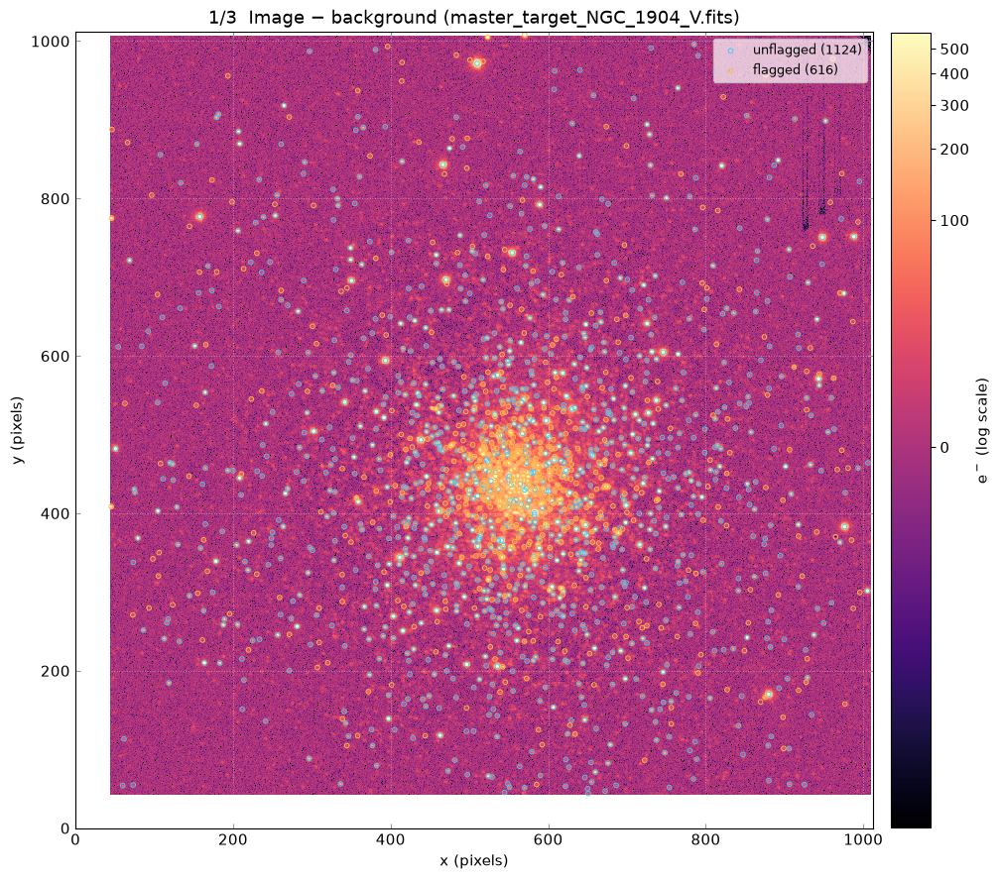

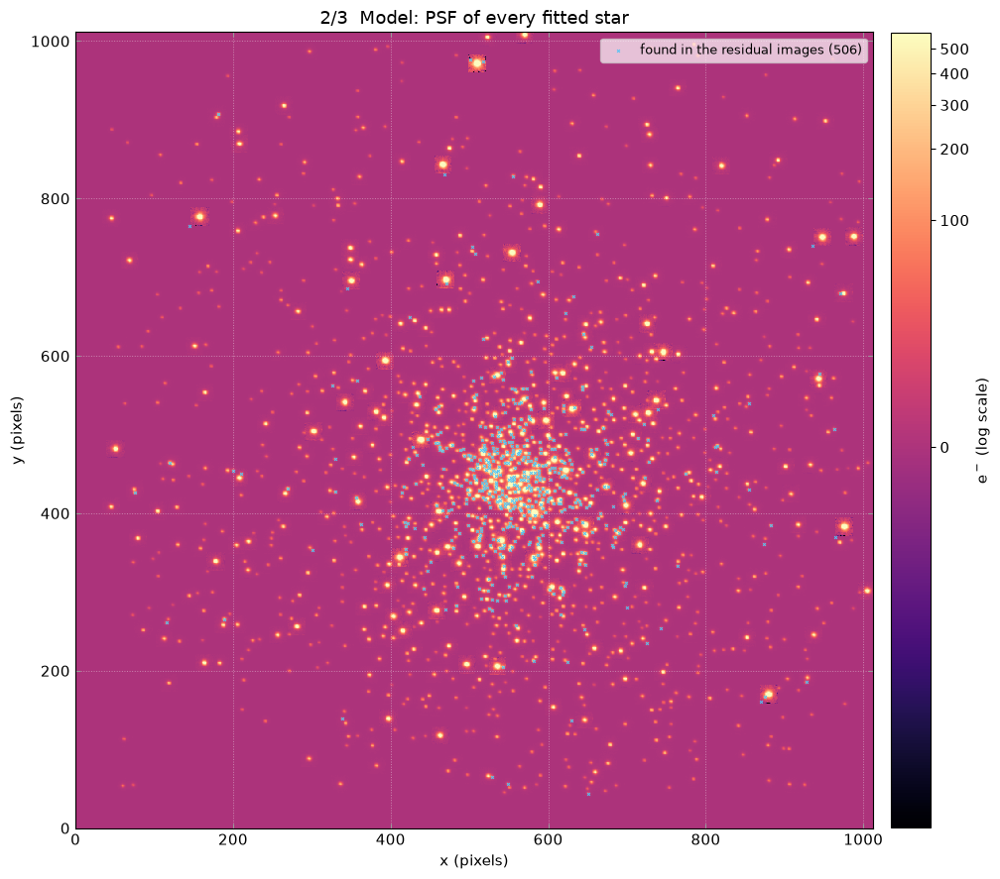

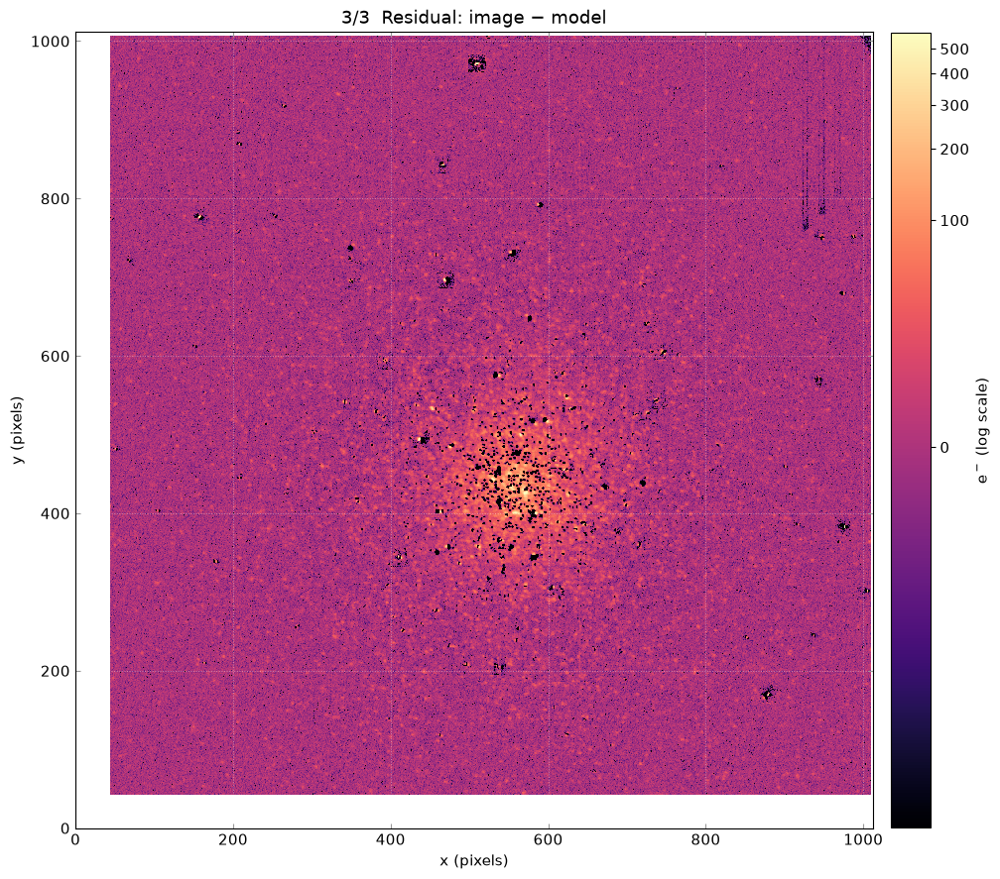

master_target_NGC_1904_R.fits: FWHM = 2.81 px (0.68 arcsec), scatter 0.17 px from 39 stars; sky = 54.6 e-, RMS = 5.62 e-; 1888 sources above 5.0 sigma
master_target_NGC_1904_R.fits: empirical PSF from 30 stars (stamp 21 px, oversampling 2)
   iteration 1: 1888 stars fitted (grouping distance 2.00 FWHM), 653 new stars found in the residual image
   iteration 2: 2541 stars fitted (grouping distance 2.00 FWHM), 183 new stars found in the residual image
master_target_NGC_1904_R.fits: 2691 stars (1512 unflagged); PSF-to-total correction +0.005 mag from 20 stars; background noise factor 1.06


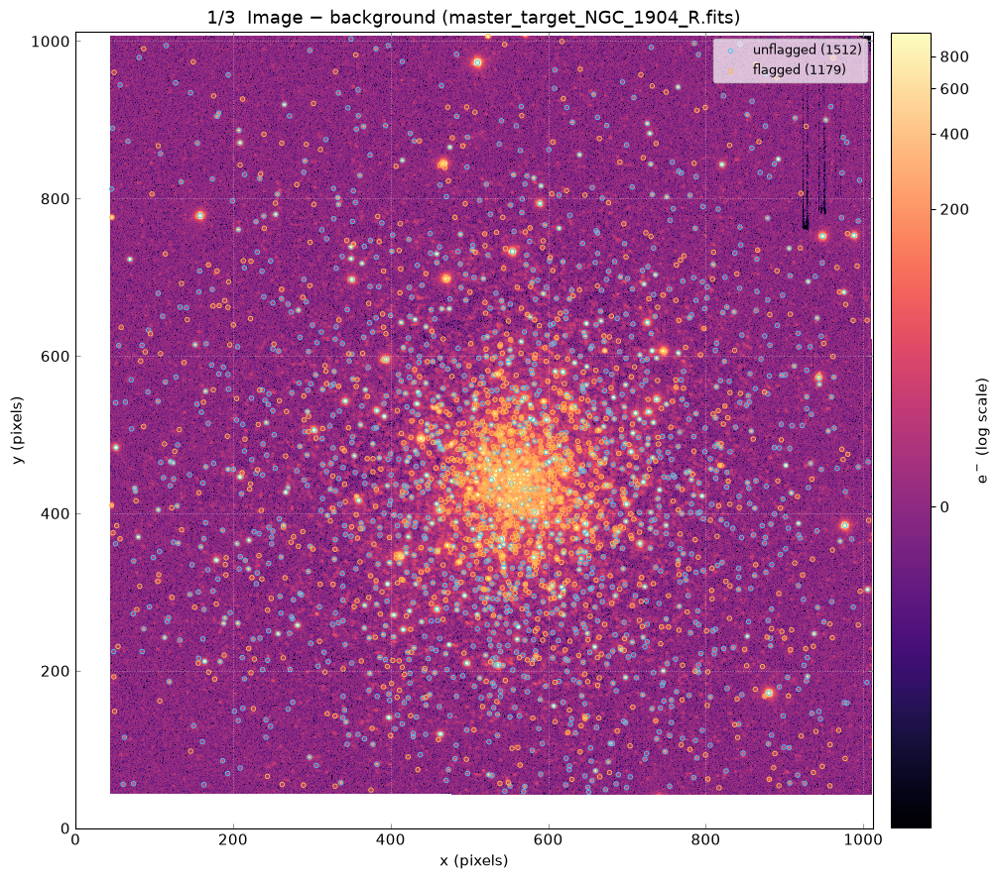

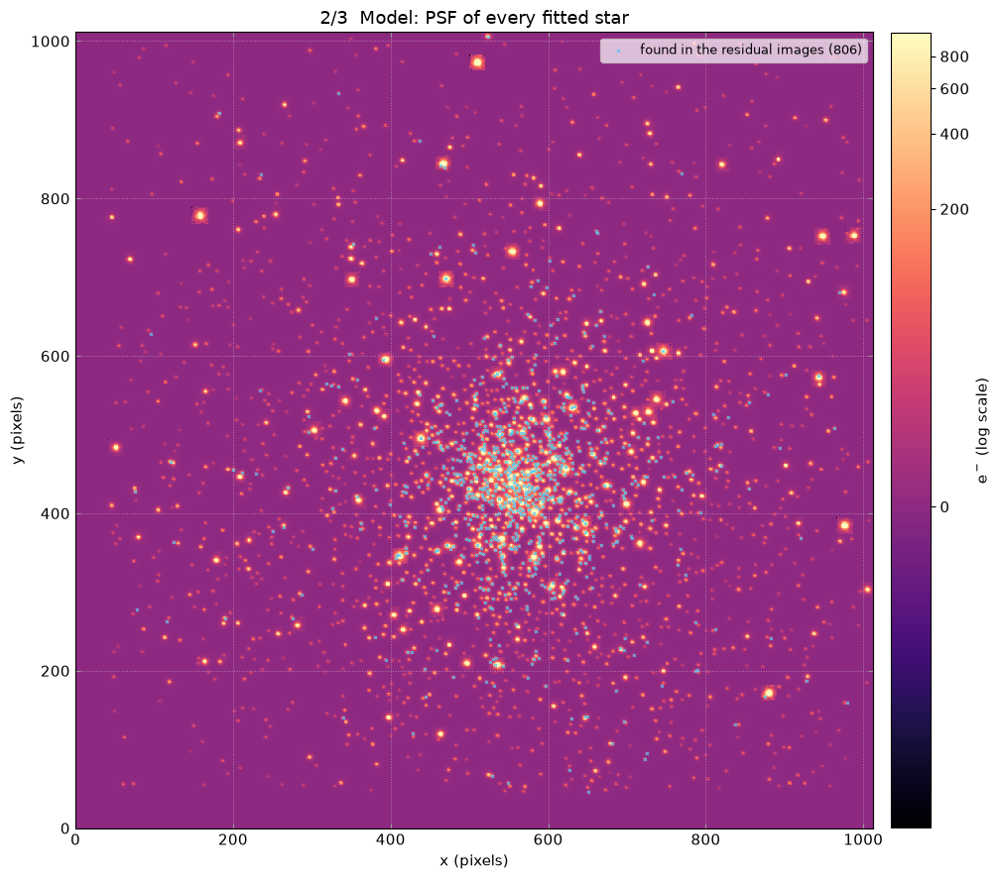

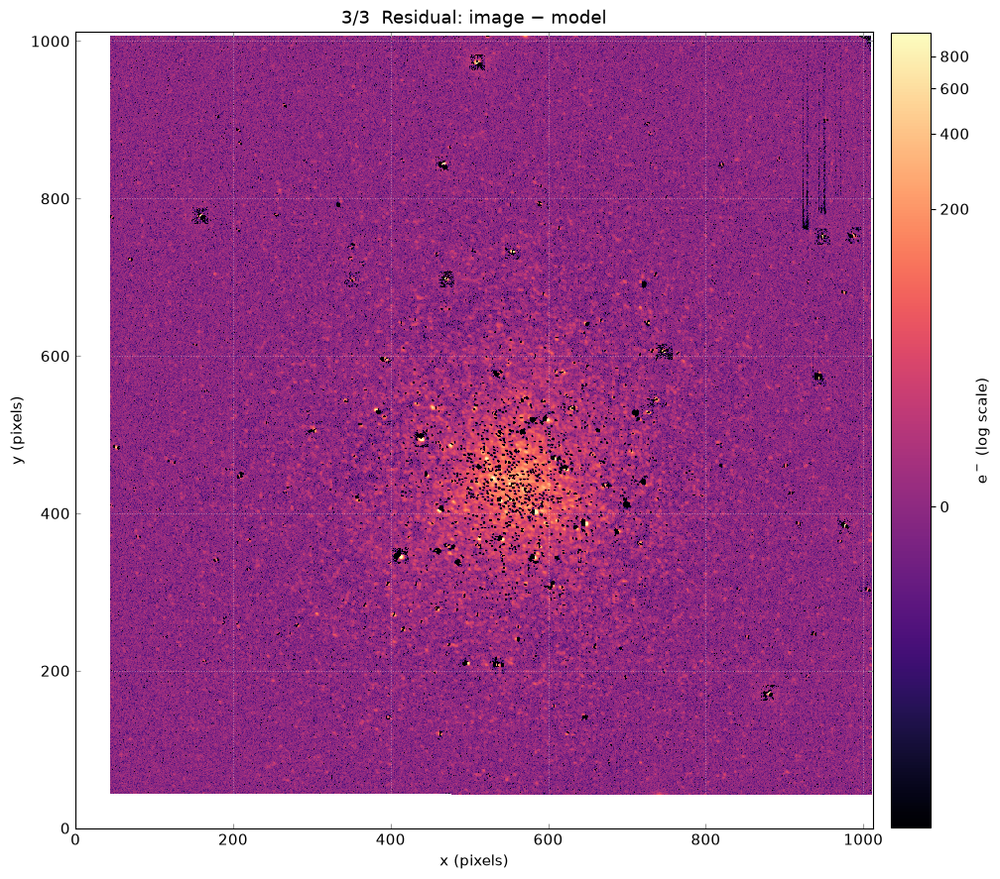

In [8]:
# All the options are at their default values: phot.psf_photometry(cluster) would give exactly the same result
B_psf, V_psf, R_psf = phot.psf_photometry(cluster,
                                          number_of_psf_stars=30,          # maximum number of bright isolated stars that build the PSF
                                          psf_oversampling=2,              # sub-pixel sampling of the empirical PSF (4 needs many more stars)
                                          fit_size=2.0,                    # size of the fitting box, in FWHM (the core of each star)
                                          grouping_separation=2.0,         # stars closer than this (FWHM) are fitted together
                                          number_of_iterations=3,          # cycles of fit + search for hidden stars in the residuals
                                          residual_detection_threshold=5.0,   # threshold (sigma) for new stars in the residual images
                                          psf_model_error_fraction=0.05,   # assumed error of the PSF model (5%), so that its residuals
                                                                           # around bright stars are not taken as new stars
                                          correction_radius=4.0,           # "total" aperture of the PSF-to-total correction, in FWHM
                                          detection_threshold=5.0,         # first detection (sigma), as in find_stars()
                                          fwhm="auto",                     # measured on the image, or a value in pixels
                                          background_box_size=32,          # small boxes: the background follows the diffuse light
                                          plot=True,                       # image, model and residual of each band, one after the other
                                          plot_region=None,                # e.g. ((460, 660), (335, 535)): zoom on the core
                                          image_scale="log",               # "log" or "linear" (linear shows the true sign of the residuals)
                                          verbose=True)

# To look closely at the core (x1, x2), (y1, y2) in pixels, in linear scale:
# phot.plot_psf_photometry(cluster[1], region=((460, 660), (335, 535)), image_scale="linear")

How to read the three figures of each band (same intensity scale, so they can be compared directly):

1. **Image − background**: what the detector recorded. Blue circles are unflagged stars, orange circles are flagged ones (saturated,
   crowded, poor fit).
2. **Model**: the PSF of every fitted star, at its fitted position and flux. Crosses mark the stars found in the residual images.
3. **Residual = image − model**: what the fit did not explain. Away from the core, only noise should remain (and the cores of saturated
   stars, which cannot be modelled). In the core of the cluster the residual is the light of the stars too faint to be detected: this is
   the light measured by the surface photometry below.

The same color-magnitude diagram from both methods: PSF photometry measures more stars in the crowded core, with smaller scatter.

master_target_NGC_1904_V.fits -> master_target_NGC_1904_B.fits: offset dx = -0.42, dy = -0.80 px; 938 stars matched
938 stars with B and V; calibration (systematic) uncertainty: B 0.014, V 0.010, B-V 0.017 mag
master_target_NGC_1904_R.fits -> master_target_NGC_1904_V.fits: offset dx = -0.33, dy = -1.46 px; 1610 stars matched
1610 stars with V and R; calibration (systematic) uncertainty: V 0.010, R 0.011, V-R 0.015 mag


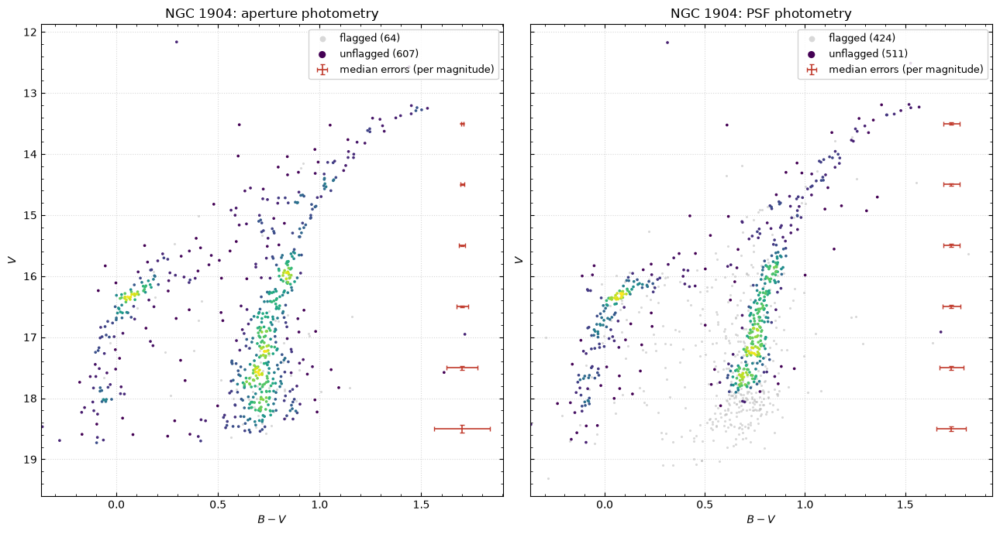

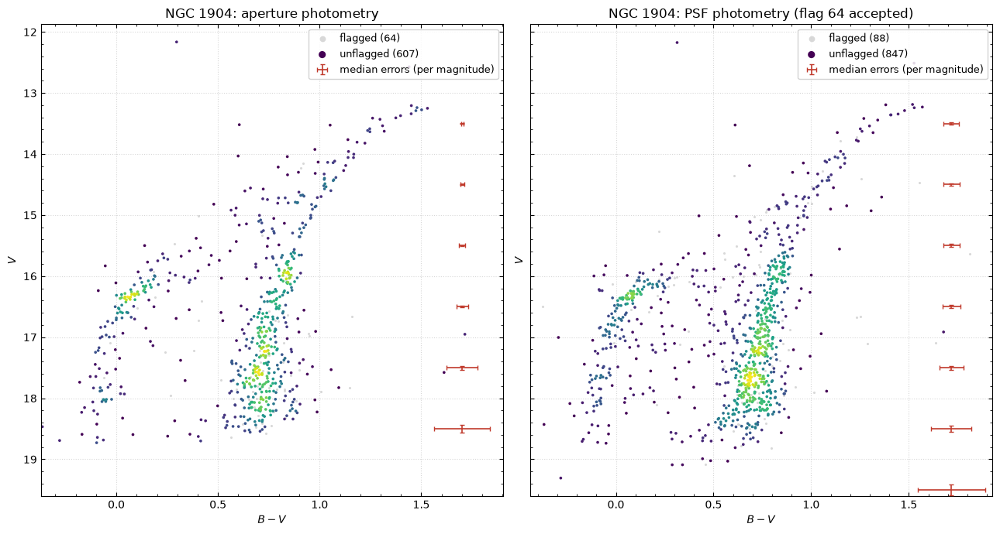

PosixPath('photometry_output_globular/NGC1904_VR_psf.csv')

In [9]:
psf_BV = phot.calibrate_magnitudes([B_psf, V_psf], solution_BV)
psf_VR = phot.calibrate_magnitudes([V_psf, R_psf], solution_VR)

# Only non-flagged stars:
figure, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
phot.plot_color_magnitude_diagram(aperture_BV, title="NGC 1904: aperture photometry", axis=axes[0])
phot.plot_color_magnitude_diagram(psf_BV, title="NGC 1904: PSF photometry", axis=axes[1])
plt.tight_layout()

# Including stars flagged as 64:
figure, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
phot.plot_color_magnitude_diagram(aperture_BV, title="NGC 1904: aperture photometry", axis=axes[0])
phot.plot_color_magnitude_diagram(psf_BV, accepted_flags=64,          # stars with only a "poor PSF fit" flag are shown as good ones
                                  title="NGC 1904: PSF photometry (flag 64 accepted)", axis=axes[1])
plt.tight_layout()
plt.show()

phot.save_table(psf_BV, out/"NGC1904_BV_psf.csv")
phot.save_table(psf_VR, out/"NGC1904_VR_psf.csv")

Both diagrams show the classic sequences of an old, metal-poor globular cluster: the red giant branch, rising to V ≈ 13 at B − V ≈ 1.5;
the asymptotic giant branch, just bluer than it; and the horizontal branch, at V ≈ 16.2 and B − V ≈ 0-0.2, with the long blue tail
typical of M79, reaching V ≈ 18.5. The scattered stars between the two branches are mostly RR Lyrae variables, caught at random phases.
The 1-s exposures do not reach the main-sequence turnoff (V ≈ 19.5-20).

The PSF photometry gives narrower sequences, especially in the crowded core. Its flagged stars (grey) are mostly faint stars with a
poor PSF fit (flag 64): many of them lie on the giant branch, so they are real cluster members measured with low signal-to-noise.

## 5. Surface photometry

The light of a cluster can also be measured as a surface brightness (mag/arcsec²) as a function of the distance to the centre, which
gives its structure (core radius, concentration) even where the stars cannot be separated. `surface_photometry()` does everything in one
call, for each band:

1. finds the centre of the light;
2. subtracts the PSF models of the stars fitted above (so `psf_photometry()` must be run first), and masks the cores of saturated stars;
3. measures the mean intensity (sigma-clipped) in annuli around the centre. Because fewer stars are resolved in the crowded core, the
   remaining light alone would look more concentrated than the cluster: `add_back_resolved_stars=True` adds the (noise-free) fitted
   fluxes back to their annuli, giving the total surface brightness;
4. fits a King (1962) model, the classic profile of globular clusters, plus a constant sky. M79 fills the whole field of EFOSC (about
   4' x 4'), so the sky cannot be measured "outside" it: it is a free parameter of the fit. The tidal radius (where the cluster ends,
   about 500" according to Lanzoni et al. 2007) is far beyond the field, so it is fixed with `fixed_parameters`;
5. calibrates the profiles in mag/arcsec² with the standard-star solution, which also gives the color profile. The solution must
   contain the bands of the images: here B and V, with `solution_BV`.

With `plot=True` (default) it plots the profiles of all bands; with `plot_annuli=True` it also shows each image with the annuli in which
the surface brightness is measured (circular here; elliptical with `ellipticity` > 0), the centre and the core radius. The annuli are
logarithmically spaced, so the inner ones are shown enlarged in an inset. The results are saved as tables in `output_directory`: the
profile of each band, the fitted parameters, and the calibrated profile. For galaxies, use `fit_isophotes=True` (elliptical isophotes,
which give the ellipticity and orientation of the annuli) and `profile_model="sersic"`.

master_target_NGC_1904_B.fits: profile in 15 annuli from 0.5 to 89.7 arcsec; centre (559.2, 434.9), ellipticity 0.000, position angle 0.0 deg
King fit (master_target_NGC_1904_B.fits): I_0 = 2820 +/- 3.1e+02 e-/s/arcsec^2 (instrumental mu_0 = -8.626), r_c = 12.36 +/- 0.93 arcsec, r_t = 500.0 +/- 0.0 arcsec, sky = 585.9 +/- 4.7; reduced chi2 = 0.46
master_target_NGC_1904_V.fits: profile in 15 annuli from 0.4 to 89.2 arcsec; centre (560.2, 433.1), ellipticity 0.000, position angle 0.0 deg
King fit (master_target_NGC_1904_V.fits): I_0 = 4203 +/- 8.1e+02 e-/s/arcsec^2 (instrumental mu_0 = -9.059), r_c = 15.71 +/- 2.30 arcsec, r_t = 500.0 +/- 0.0 arcsec, sky = 754.5 +/- 26; reduced chi2 = 2.35
Calibrated central surface brightness: B = 17.022 +/- 0.125, V = 16.724 +/- 0.202 mag/arcsec^2, B-V = 0.297
Saved: photometry_output_globular/M79_surface_profile_B.ecsv, photometry_output_globular/M79_surface_profile_V.ecsv, photometry_output_globular/M79_surface_profile_fits.ecsv, photometry_output_gl

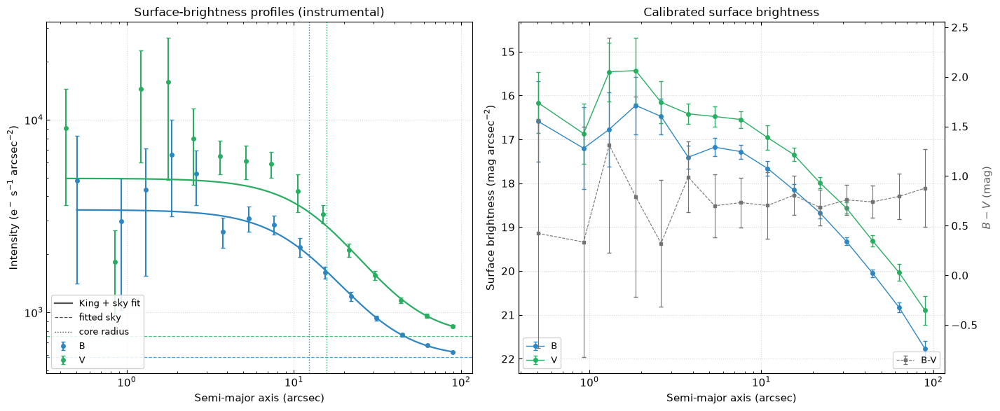

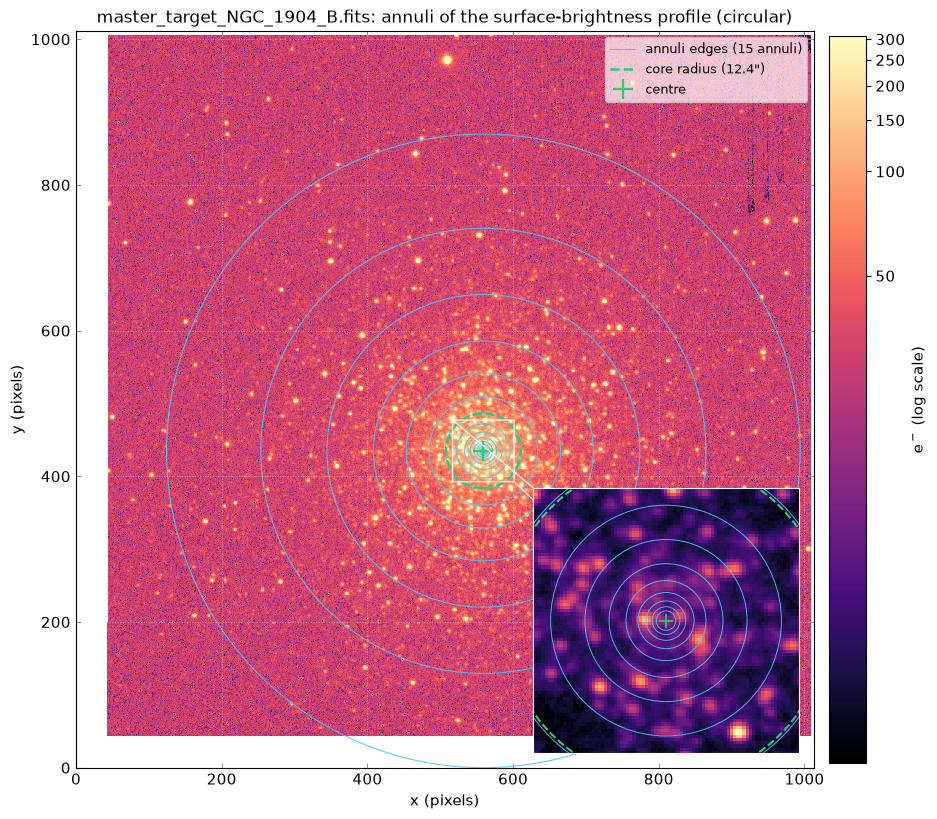

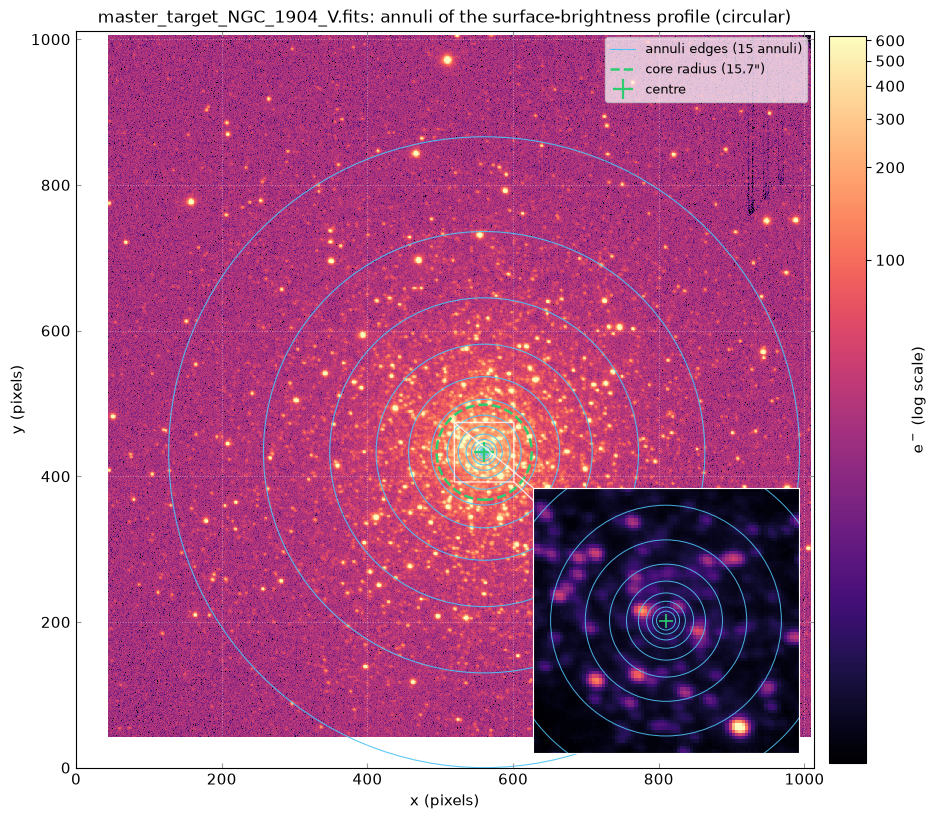

In [10]:
B_image, V_image, R_image = cluster                     # the images measured with psf_photometry() above

surface = phot.surface_photometry([B_image, V_image],              # one image per band
                                  solution=solution_BV,            # standard-star solution with these bands (for mag/arcsec^2)
                                  profile_model="king",            # "king" (clusters), "sersic" (galaxies) or None (no fit)
                                  fixed_parameters={"tidal_radius": 500.0},   # arcsec (Lanzoni et al. 2007): far beyond the field
                                  remove_stars="psf",              # subtract the PSF models of psf_photometry(); or "mask", or None
                                  add_back_resolved_stars=True,    # total surface brightness: resolved + unresolved light
                                  center="auto",                   # centre of the light; or (x, y) in pixels
                                  ellipticity=0.0,                 # circular annuli (1 - b/a)
                                  position_angle=0.0,              # degrees, counter-clockwise from +x (only for ellipticity > 0)
                                  fit_isophotes=False,             # True: measure the shape with elliptical isophotes (galaxies)
                                  minimum_radius=None,             # pixels; default: 1 FWHM
                                  maximum_radius=None,             # pixels; default: the largest radius within the image
                                  number_of_annuli=15,             # logarithmically spaced
                                  save_results=True,               # profiles, fits and calibrated profile as tables (.ecsv)
                                  output_directory=out,
                                  file_prefix=None,                # default: the OBJECT of the header (here "M79")
                                  plot=True,                       # profiles of all bands, calibrated profile and color
                                  plot_annuli=True,                # each image with its annuli, the centre and the core radius
                                  image_scale="log",
                                  verbose=True)

The centre is found at the same place in B and V (within 2 pixels), and the profiles are well described by the King model plus sky. The
core radius is ≈12" in B and ≈16" in V (see the values printed above), close to the 9.7 ± 2" found by Lanzoni et al. (2007) for M79.
Inside a few arcseconds the profile is still noisy: each annulus there contains only a handful of bright giants, and their light (added
back with `add_back_resolved_stars=True`) changes a lot from one annulus to the next. These are stochastic fluctuations of a few stars,
not photometric noise. They are why we used `number_of_annuli=15`: wider annuli contain more stars each, so the core is more stable.
With narrow annuli (30) the fluctuations were larger, especially in V, where the red giants dominate the light even more, and the two
bands gave very different core radii.

The color profile is flat, with B − V ≈ 0.7-0.8 from ~4" to the edge of the field: within the errors, the cluster has the same color at
all radii. The "central" B − V printed above comes from the two King fits, which have slightly different core radii, so it is not a
physical color: use the color profile instead.

Everything is in the returned dictionary: `surface["profiles"]` (one table per band, with the radius, intensity and error of each
annulus), `surface["fits"]` (fitted parameters, errors and the model as a function of radius) and `surface["calibrated_profile"]` (mag/arcsec²
and color); `surface["files"]` lists the saved tables, which can be read back with `Table.read(file_name)`. Making your own plot is
simple:

{'tidal_radius': 500.0, 'central_intensity': np.float64(2819.8935584827286), 'core_radius': np.float64(12.35904511573423), 'sky': np.float64(585.856694819264)}
core radius: 12.4 +/- 0.9 arcsec (Lanzoni et al. 2007: 9.7 +/- 2)


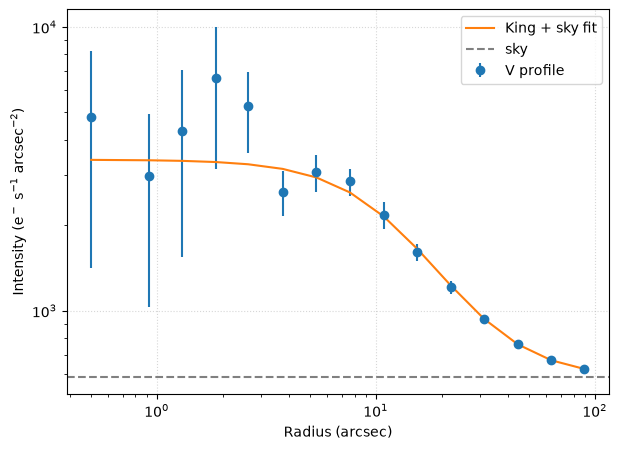

In [11]:
profile = surface["profiles"]["B"]      # an astropy Table: one row per annulus
king_fit = surface["fits"]["B"]         # a dictionary: "values", "errors", "model", ...
print(king_fit["values"])
print(f"core radius: {king_fit['values']['core_radius']:.1f} +/- {king_fit['errors']['core_radius']:.1f} arcsec "
      "(Lanzoni et al. 2007: 9.7 +/- 2)")

radius = profile["radius_arcsec"]
plt.figure(figsize=(7, 5))
plt.errorbar(radius, profile["intensity"], yerr=profile["intensity_error"], fmt="o", label="V profile")
plt.plot(radius, king_fit["model"](radius), label="King + sky fit")
plt.axhline(king_fit["values"]["sky"], linestyle="--", color="gray", label="sky")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Radius (arcsec)")
plt.ylabel("Intensity (e$^-$ s$^{-1}$ arcsec$^{-2}$)")
plt.grid(linestyle=":", alpha=0.5)
plt.legend()
plt.show()